# Intermediate Machine Learning: Assignment 3

**Deadline**

Assignment 3 is due Thursday, October 30 by 11:59pm. Late work will not be accepted as per the course policies (see the Syllabus and Course policies on Canvas).

Directly sharing answers is not okay, but discussing problems with the course staff or with other students is encouraged. Acknowledge any use of an AI system such as ChatGPT or Copilot.


You should start early so that you have time to get help if you're stuck. The drop-in office hours schedule can be found on Canvas. You can also post questions or start discussions on Ed Discussion. The assignment may look long at first glance, but the problems are broken up into steps that should help you to make steady progress.

**Submission**

Submit your assignment as a pdf file on Gradescope, and as a notebook (.ipynb) on Canvas. You can access Gradescope through Canvas on the left-side of the class home page. The problems in each homework assignment are numbered. Note: When submitting on Gradescope, please select the correct pages of your pdf that correspond to each problem. This will allow graders to more easily find your complete solution to each problem.

To produce the .pdf, please convert to html and then print to pdf. (You may want to use your pdf print menu to scale the pages to be sure that cells are not truncated.) To convert to html, you can use this [converter notebook](https://colab.research.google.com/github/YData123/sds365-fa25/blob/main/assignments/Convert_ipynb_to_HTML_in_Colab.ipynb).

**Topics**

 * Variational autoencoders (VAEs)
 * Undirected graphs
 * The graphical lasso



## Problem 1: Face time (35 points)

In this problem, we will implement a "shoestring" version of [this amazing fake face generator](https://www.nytimes.com/interactive/2020/11/21/science/artificial-intelligence-fake-people-faces.html), using a variational autoencoder (VAE). Building a generator like the one featured in the article can take a tremendous amount of computational resources, time, and parameter tuning. In this problem we will build a basic version to illustrate the main concepts, and help you to become more famililar with VAEs.  Here is an outline of the process that we'll step you through:

### Problem outline:

* Load data
* Create face groups based on attributes
* Construct the VAE
* Define the loss function and train the VAE (Problem 1.1)
* Encode and reconstruct faces (Problem 1.2)
* Visualize the latent space (Problem 1.3)
* Morph between faces (Problem 1.4)
* Shift attributes of faces (Problem 1.5)
* Generate new faces (Problem 1.6)
* Analyze the effect of the scaling factor in the loss function (Problem 1.7, optional)

In the next cell we load the packages that we'll need. If you don't have one or more of these, you can install them with `!pip install <package_name>` in the cell, or outside the notebook
with `conda install -c conda-forge <package_name>`

In [2]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import os
import glob
import pandas as pd
import random
import numpy as np
import imageio
from tqdm import tqdm
from PIL import Image
from sklearn.model_selection import train_test_split
from scipy.stats import norm
import tensorflow
# tensorflow.compat.v1.disable_eager_execution()

In [1]:
import platform, tensorflow as tf
print(platform.machine())                 # expect: arm64
print(tf.__version__)                     # expect: 2.16.2
print(tf.config.list_physical_devices())  # CPU and a "GPU" via Metal

arm64
2.16.2
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Loading the data

[Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/) (LFW) is a database of face photographs. The images are placed in the folder lfw-deepfunneled. lfw_attributes.txt is a document including a set of attributes associated for each image, such as 'Male', 'Smile', 'Bold', etc. All the features are numerical and large positive values indicate that the keywords well describe the photo; large negative values indicate that the keywords don't fit the photo.

For this problem, we will keep only the middle parts of the photos to avoid complex backgrounds.

Download the data from the cloud at these URLs:

https://sds365.s3.amazonaws.com/lfw/lfw-deepfunneled.zip
<br>
https://sds365.s3.amazonaws.com/lfw/lfw_attributes.txt

Once you have the data, unzip it, and place it in a directory that we will call "YOUR_PATH" below.
  
Run all the cells in this section to load the data.

Note: Please write down the entire path instead of using something like '~/Desktop/datasets/' to avoid unnecessary compiling errors. Also, if you choose to use Colab to do your homework. We need to download the data into the same directory as your code. You may also need

"from google.colab import drive"

"drive.mount('/content/drive')"

to enable using paths in Google Drive before starting your code below. But personally, I would suggest using jupyter notebook to run the code locally instead of using Google Colab since the latter may take longer time.

In [3]:
# Change these path names to correspond with your directory
DATASET_PATH ="/Users/yingxuanyang/Library/CloudStorage/Dropbox/Mac/Documents/GitHub/SDS365_Assignments/assignments/assn3/lfw-deepfunneled/"
ATTRIBUTES_PATH = "/Users/yingxuanyang/Library/CloudStorage/Dropbox/Mac/Documents/GitHub/SDS365_Assignments/assignments/assn3/lfw_attributes.txt"

In [4]:

# Make sure the above path is correct before running this cell
dataset = []
for path in glob.iglob(os.path.join(DATASET_PATH, "**", "*.jpg")):
    person = path.split("/")[-2]
    dataset.append({"person":person, "path": path})

dataset = pd.DataFrame(dataset)
dataset = dataset.groupby("person").filter(lambda x: len(x) < 100 )
dataset.head(10)

,person,path
0,German_Khan,/Users/yingxuanyang/Library/CloudStorage/Dropb...
1,Stefano_Gabbana,/Users/yingxuanyang/Library/CloudStorage/Dropb...
2,Dragan_Covic,/Users/yingxuanyang/Library/CloudStorage/Dropb...
3,Jeff_Hornacek,/Users/yingxuanyang/Library/CloudStorage/Dropb...
4,Sureyya_Ayhan,/Users/yingxuanyang/Library/CloudStorage/Dropb...
5,Deb_Santos,/Users/yingxuanyang/Library/CloudStorage/Dropb...
6,Bob_Newhart,/Users/yingxuanyang/Library/CloudStorage/Dropb...
7,Wang_Hailan,/Users/yingxuanyang/Library/CloudStorage/Dropb...
8,Paul_McNulty,/Users/yingxuanyang/Library/CloudStorage/Dropb...
9,Paul_McNulty,/Users/yingxuanyang/Library/CloudStorage/Dropb...


The following cell will display some sample images

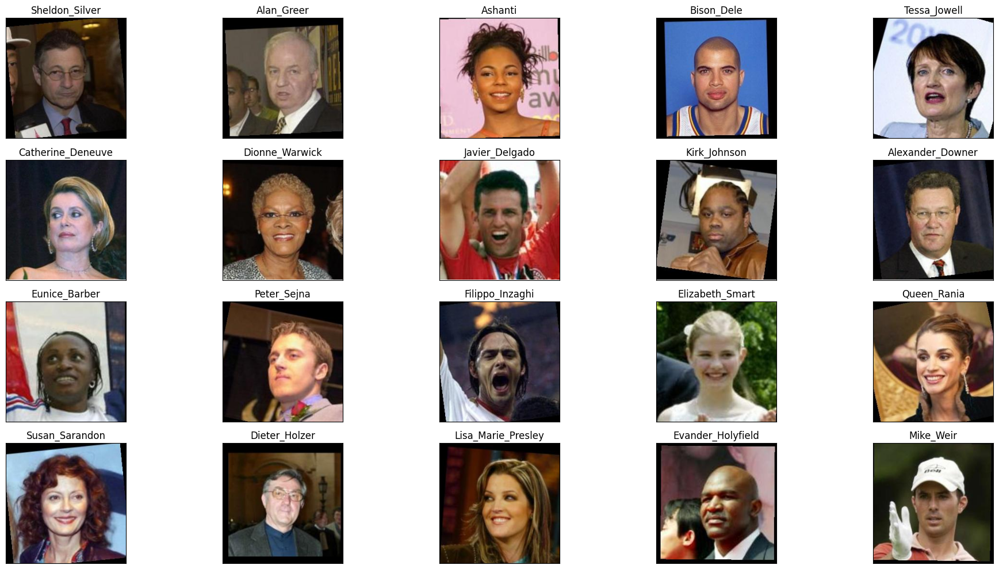

In [5]:
sampled_id = []

plt.figure(figsize=(20,10))
for i in range(20):
    idx = random.randint(0, len(dataset))
    img = plt.imread(dataset.path.iloc[idx])
    plt.subplot(4, 5, i+1)
    plt.imshow(img)
    plt.title(dataset.person.iloc[idx])
    plt.xticks([])
    plt.yticks([])
    sampled_id.append(idx)
plt.tight_layout()
plt.show()

The following cell shows the images with some of the background removed.

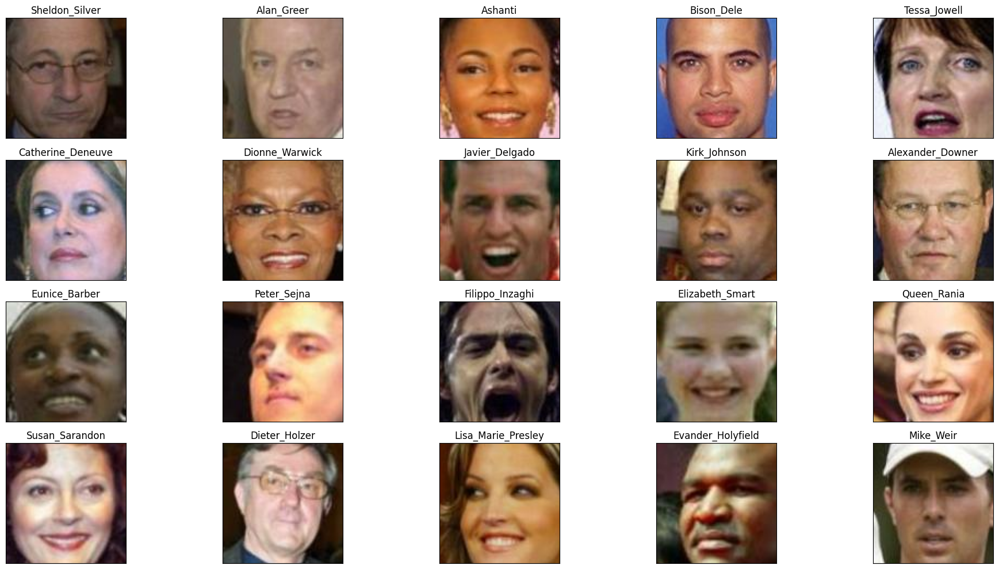

In [6]:
dx=70
dy=70

plt.figure(figsize=(20,10))
for i in range(20):
    idx = sampled_id[i]
    img = plt.imread(dataset.path.iloc[idx])
    plt.subplot(4, 5, i+1)
    plt.imshow(img[dy:-dy,dx:-dx])
    plt.title(dataset.person.iloc[idx])
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

The following function crops the images to 45x45 pixels, which is what we will use in this problem.

In [7]:
def fetch_dataset(dx=70, dy=70, dimx=45, dimy=45):

    df_attrs = pd.read_csv(ATTRIBUTES_PATH, sep='\t', skiprows=1,)
    df_attrs = pd.DataFrame(df_attrs.iloc[:,:-1].values, columns = df_attrs.columns[1:])

    photo_ids = []
    for dirpath, dirnames, filenames in os.walk(DATASET_PATH):
        for fname in filenames:
            if fname.endswith(".jpg"):
                fpath = os.path.join(dirpath,fname)
                photo_id = fname[:-4].replace('_',' ').split()
                person_id = ' '.join(photo_id[:-1])
                photo_number = int(photo_id[-1])
                photo_ids.append({'person':person_id,'imagenum':photo_number,'photo_path':fpath})

    photo_ids = pd.DataFrame(photo_ids)
    df = pd.merge(df_attrs,photo_ids,on=('person','imagenum'))

    assert len(df)==len(df_attrs),"lost some data when merging dataframes"

    all_photos = df['photo_path'].apply(imageio.imread)\
                                .apply(lambda img:img[dy:-dy,dx:-dx])\
                                .apply(lambda img: np.array(Image.fromarray(img).resize([dimx,dimy])) )

    all_photos = np.stack(all_photos.values).astype('uint8')
    all_attrs = df.drop(["photo_path","person","imagenum"],axis=1)

    return all_photos,all_attrs

The variable `data` has all the face images and the variable `attrs` has all the attributes. The 8-bit RGB values are converted to values between 0 and 1 for modeling and plotting purposes.

In [8]:
data, attrs = fetch_dataset()
data = np.array(data / 255, dtype='float32')

### Create Face Groups

We can now create groups of faces, by selecting the faces having the highest or lowest scores for each of the attributes. Run all the cells in this section to create and plot some face groups.

In [13]:
def plot_gallery(images, h, w, n_row=3, n_col=6, with_title=False, titles=[]):
    plt.figure(figsize=(1.75 * n_col, 2 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        try:
            plt.imshow(images[i].reshape((h, w, 3)), cmap=plt.cm.gray, vmin=-1, vmax=1, interpolation='nearest')
            if with_title:
                plt.title(titles[i])
            plt.xticks(())
            plt.yticks(())
        except:
            pass

In [14]:
IMAGE_H = data.shape[1]
IMAGE_W = data.shape[2]
N_CHANNELS = 3

In [15]:
smile_ids = attrs['Smiling'].sort_values(ascending=False).head(36).index.values
smile_data = data[smile_ids]

no_smile_ids = attrs['Smiling'].sort_values(ascending=True).head(36).index.values
no_smile_data = data[no_smile_ids]

eyeglasses_ids = attrs['Eyeglasses'].sort_values(ascending=False).head(36).index.values
eyeglasses_data = data[eyeglasses_ids]

sunglasses_ids = attrs['Sunglasses'].sort_values(ascending=False).head(36).index.values
sunglasses_data = data[sunglasses_ids]

mustache_ids = attrs['Mustache'].sort_values(ascending=False).head(36).index.values
mustache_data = data[mustache_ids]

male_ids = attrs['Male'].sort_values(ascending=False).head(36).index.values
male_data = data[male_ids]

female_ids = attrs['Male'].sort_values(ascending=True).head(36).index.values
female_data = data[female_ids]

eyeclosed_ids = attrs['Eyes Open'].sort_values(ascending=True).head(36).index.values
eyeclosed_data = data[eyeclosed_ids]

mouthopen_ids = attrs['Mouth Wide Open'].sort_values(ascending=False).head(36).index.values
mouthopen_data = data[mouthopen_ids]

makeup_ids = attrs['Heavy Makeup'].sort_values(ascending=False).head(36).index.values
makeup_data = data[makeup_ids]

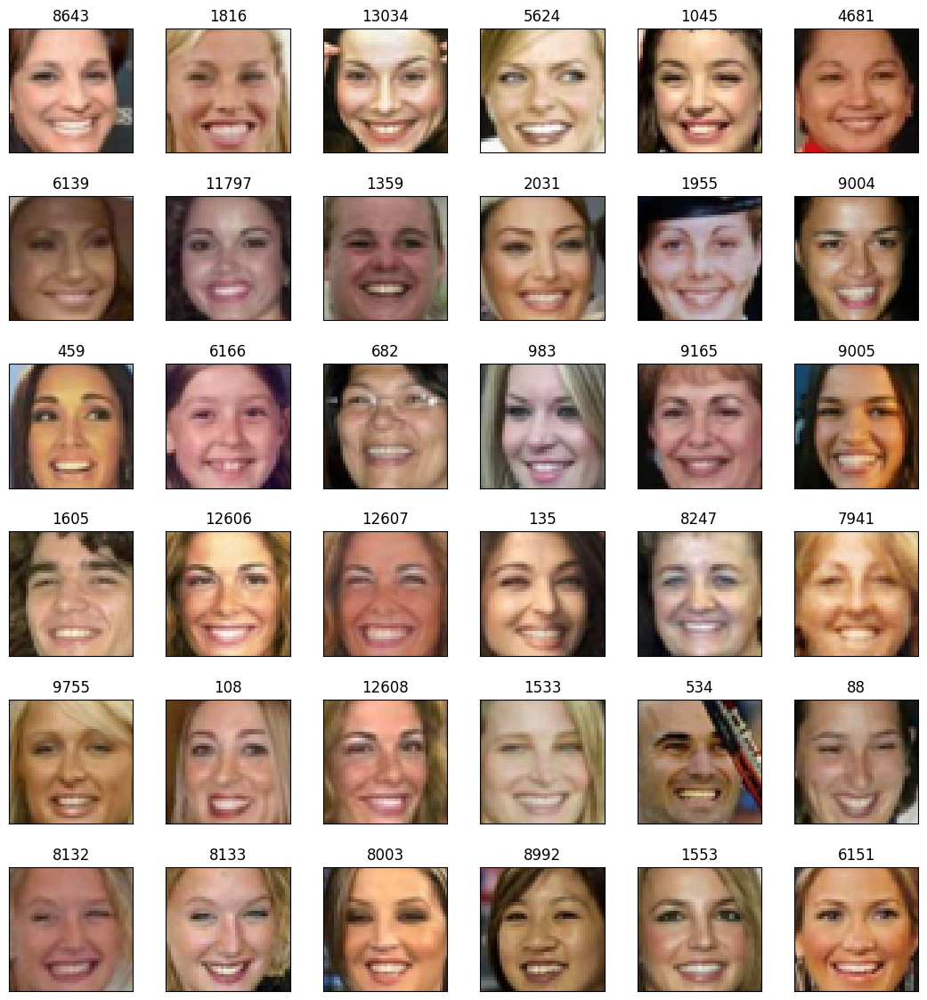

In [16]:
plot_gallery(smile_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=smile_ids)

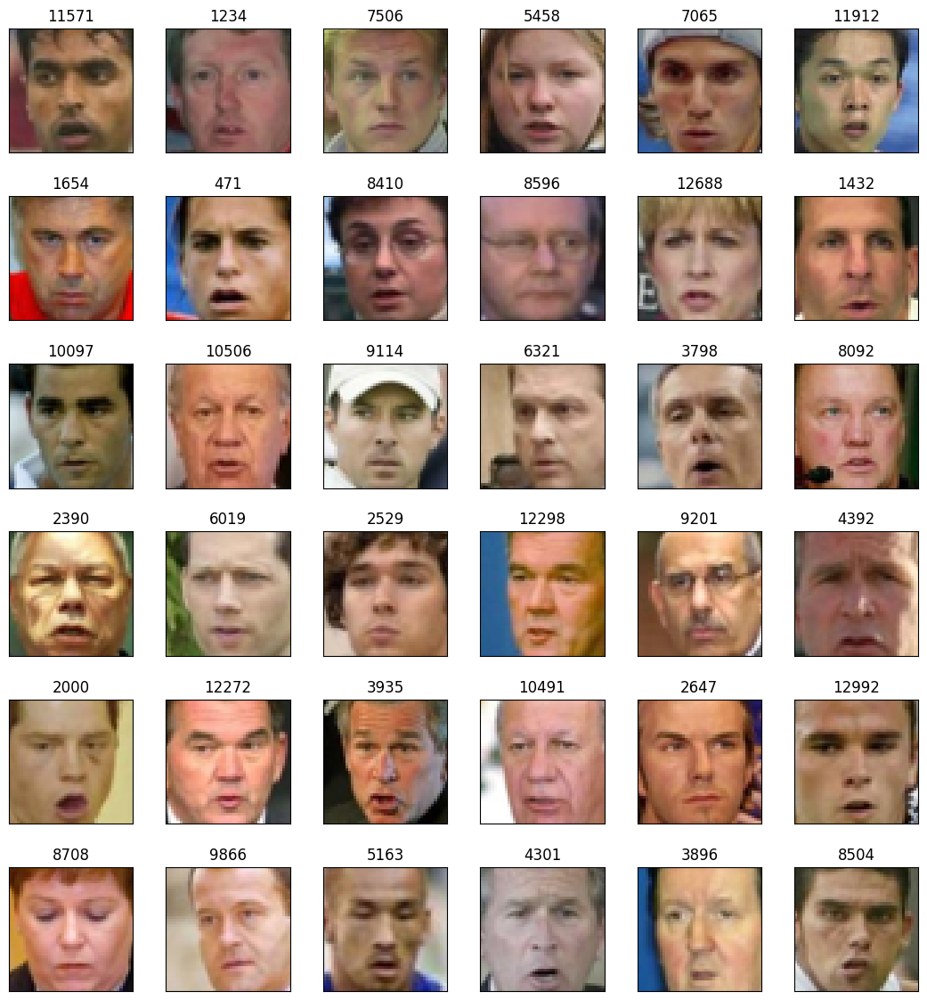

In [18]:
plot_gallery(no_smile_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=no_smile_ids)

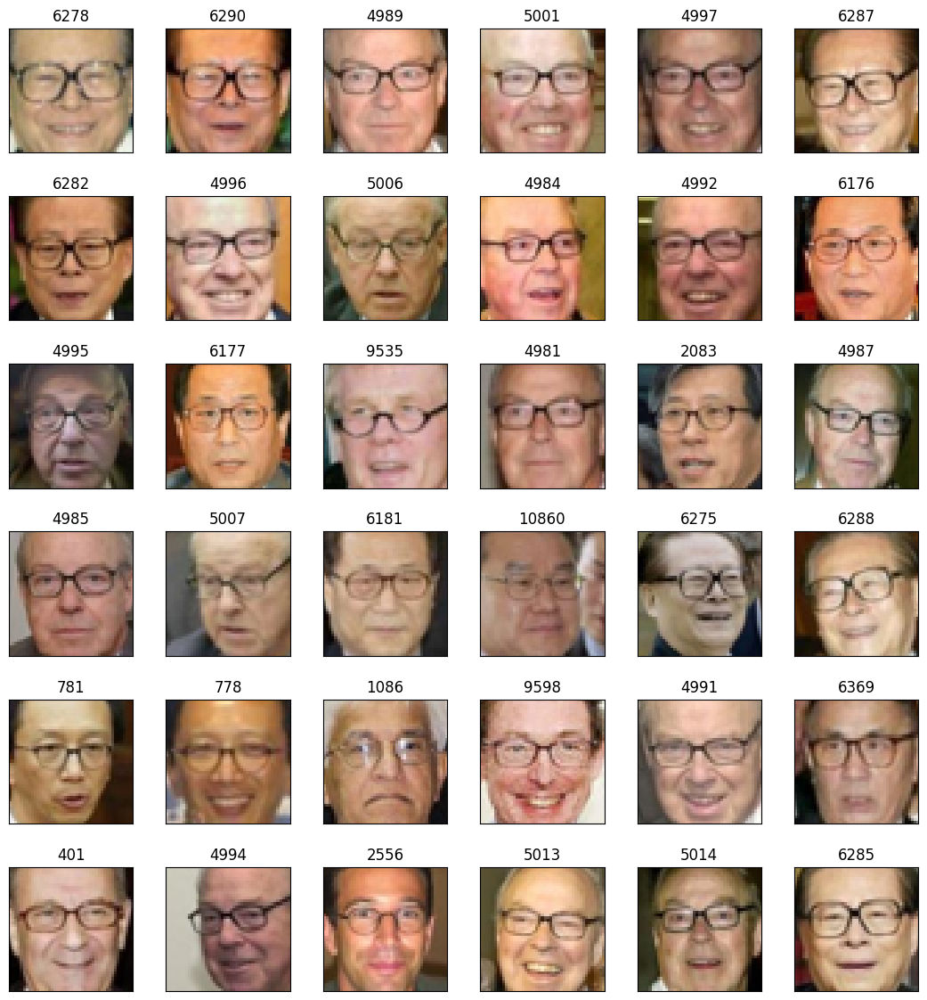

In [19]:
plot_gallery(eyeglasses_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=eyeglasses_ids)

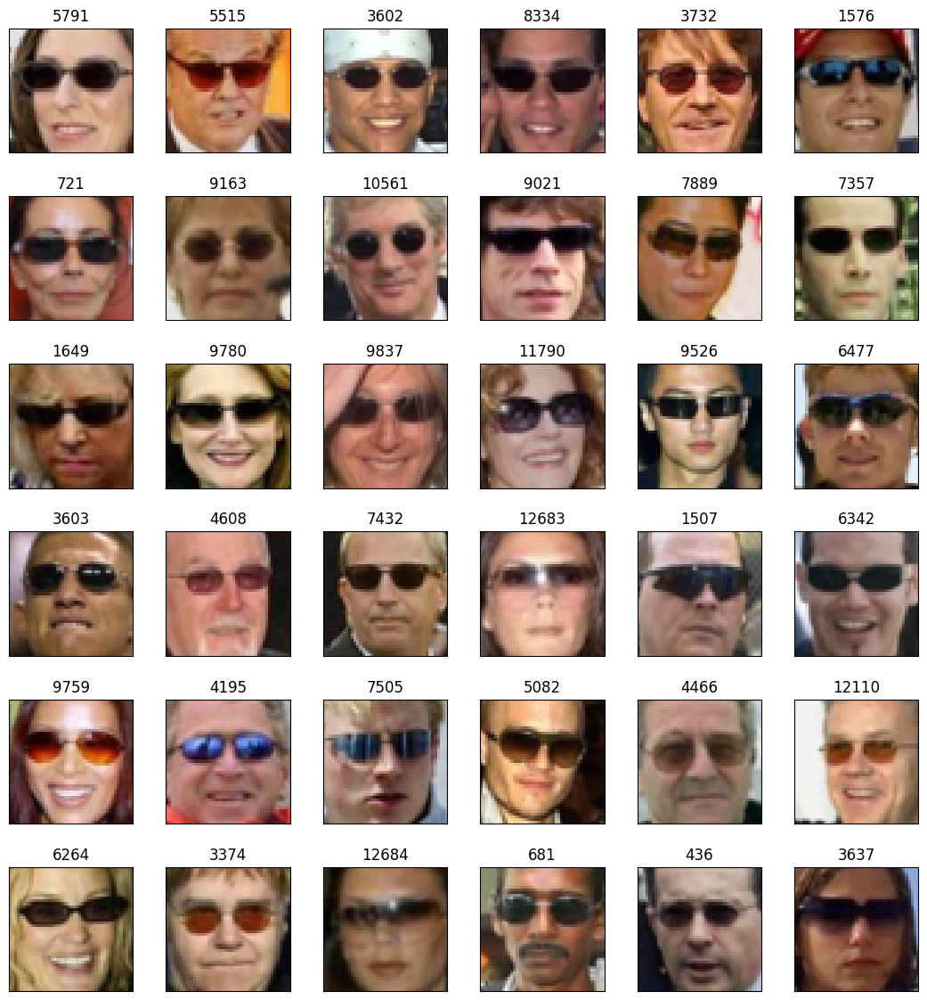

In [20]:
plot_gallery(sunglasses_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=sunglasses_ids)

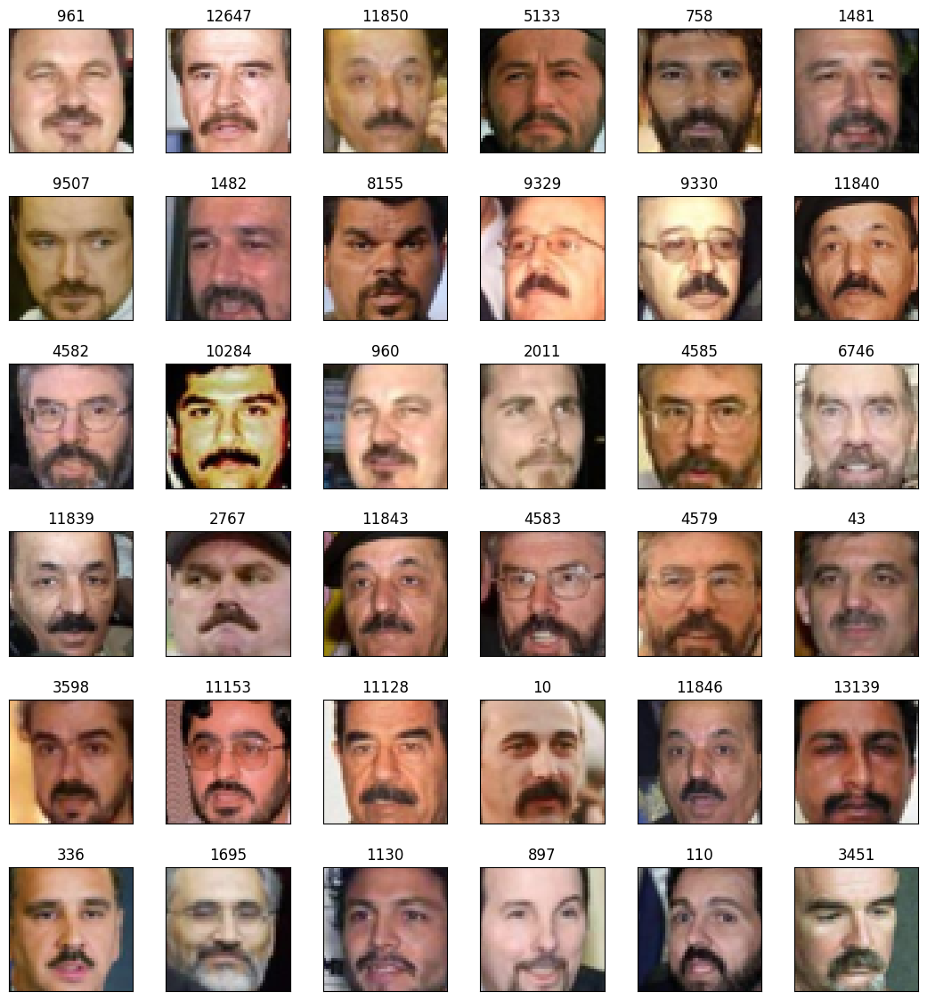

In [21]:
plot_gallery(mustache_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=mustache_ids)

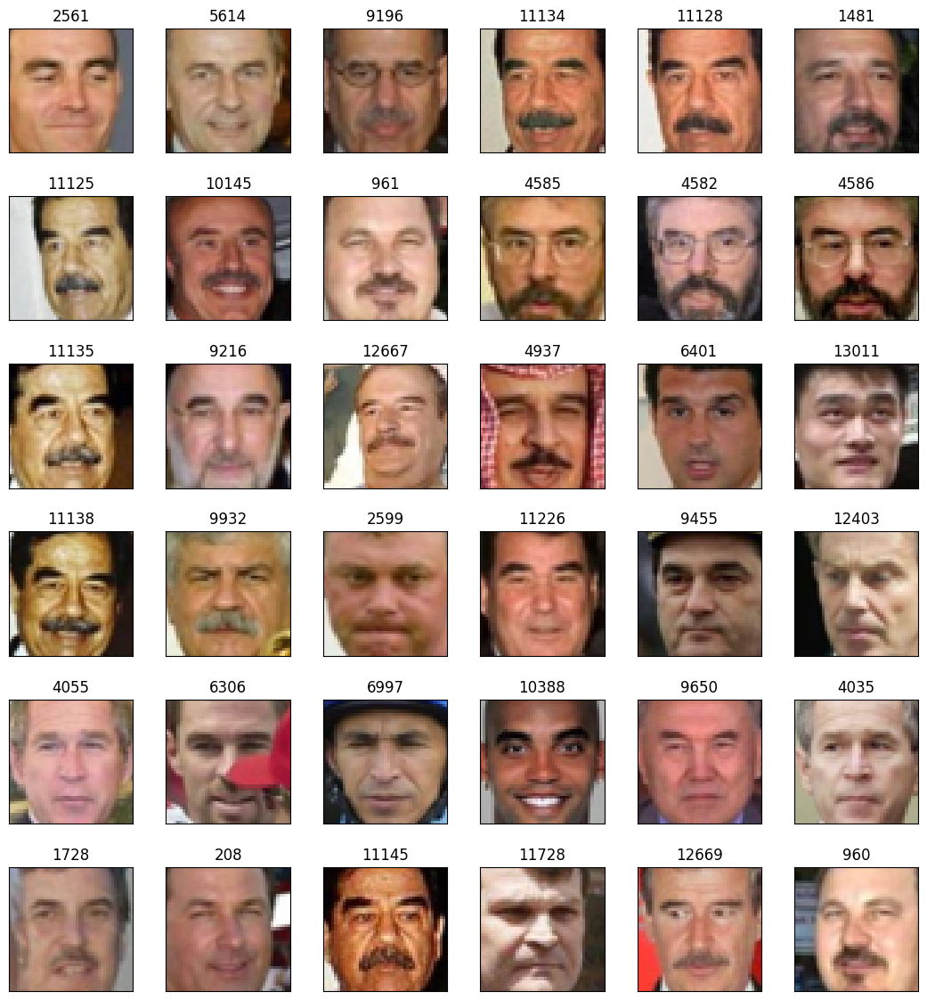

In [22]:
plot_gallery(male_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=male_ids)

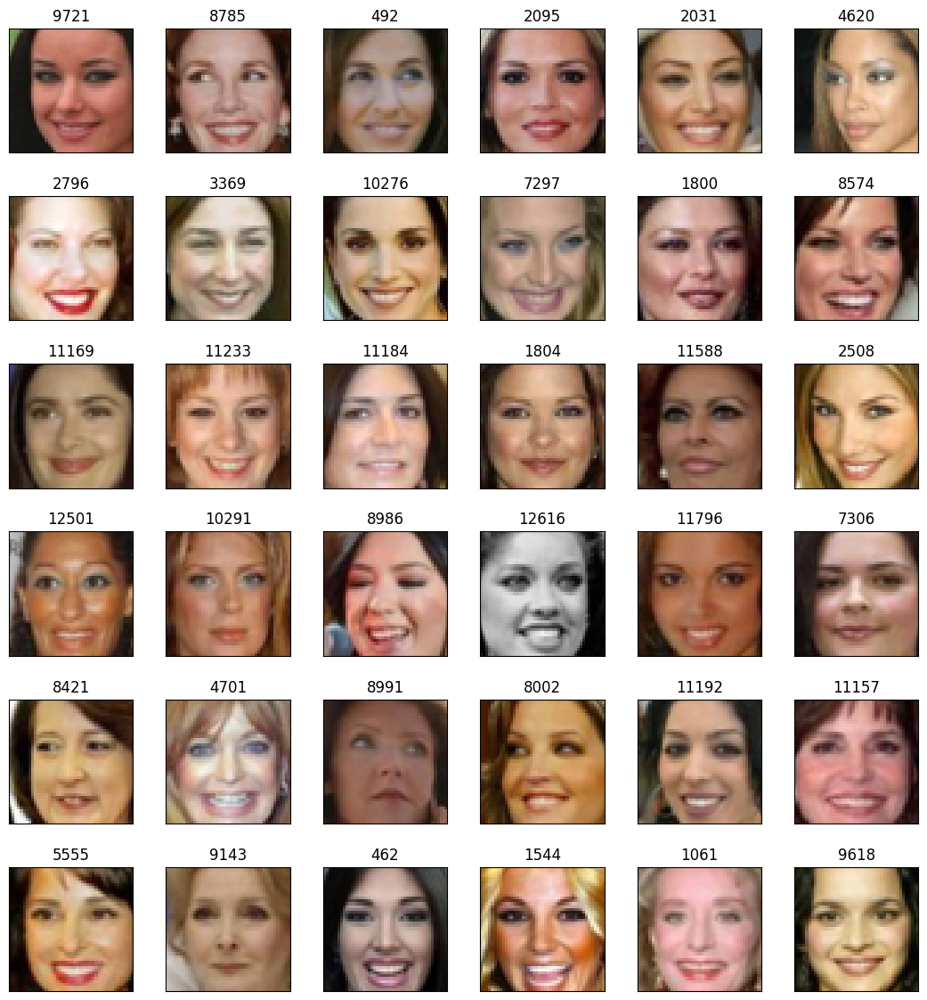

In [23]:
plot_gallery(female_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=female_ids)

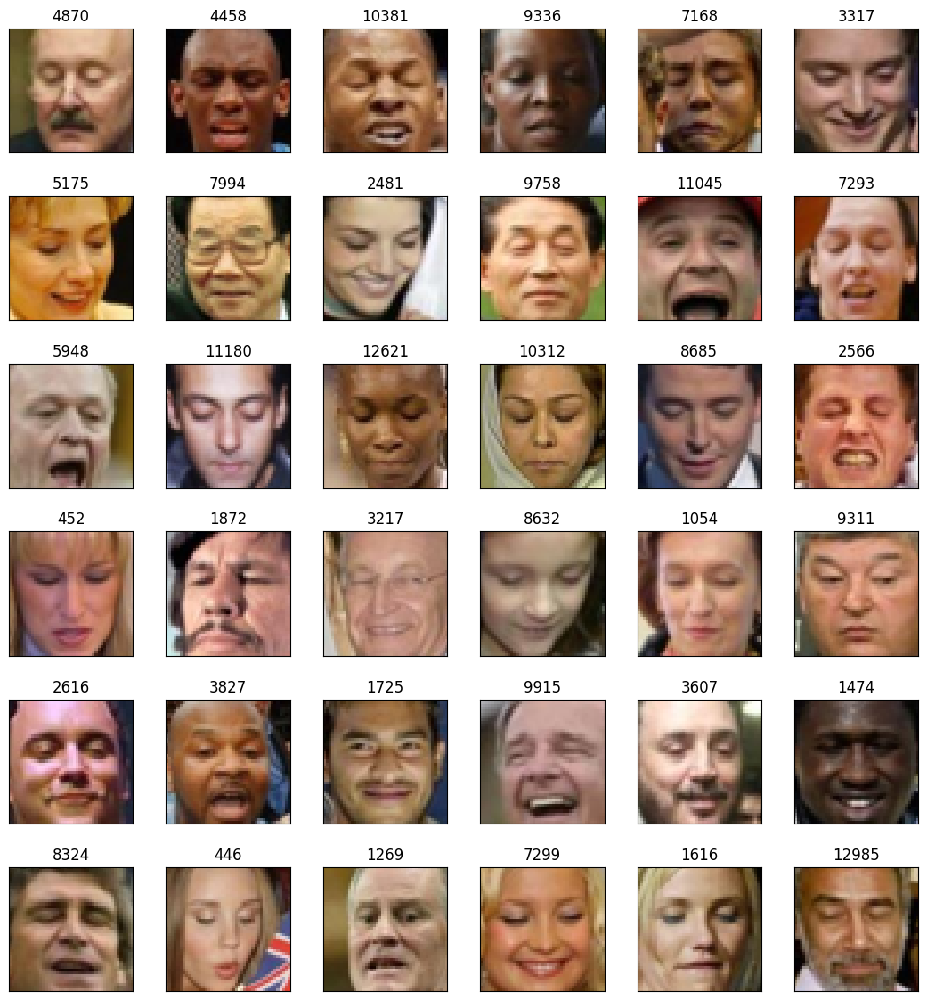

In [24]:
plot_gallery(eyeclosed_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=eyeclosed_ids)

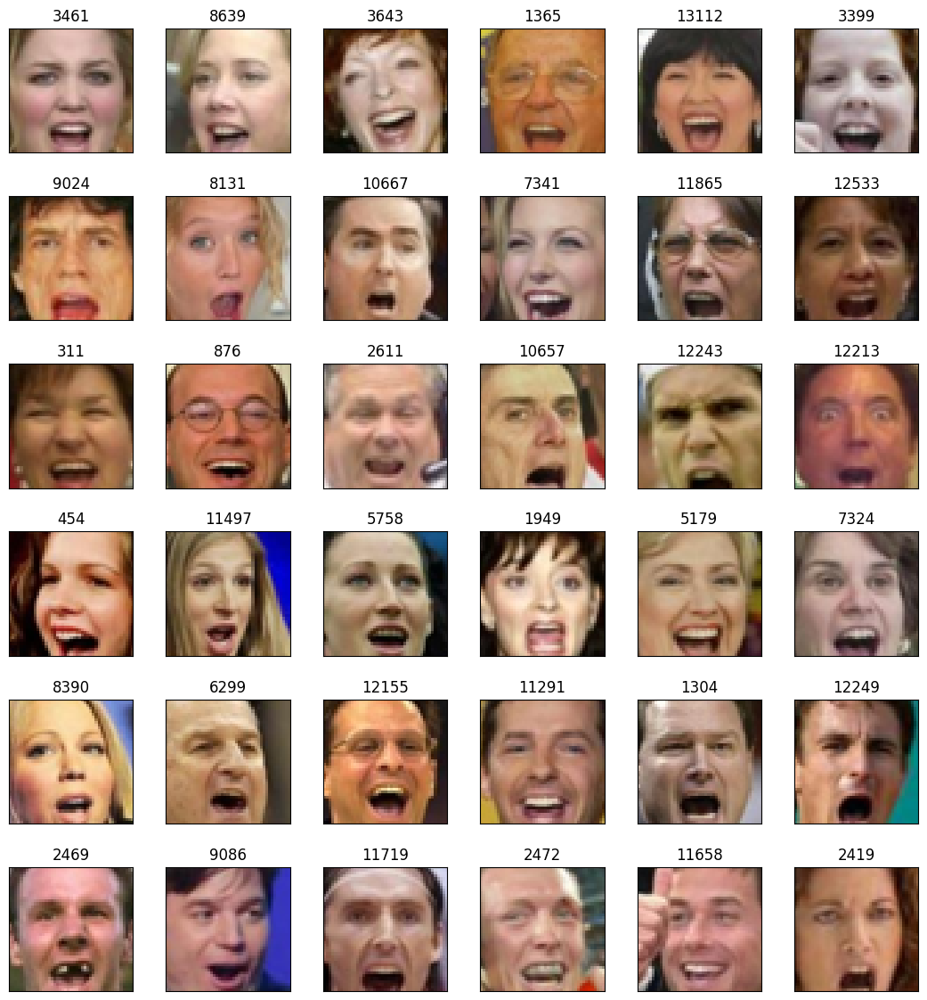

In [25]:
plot_gallery(mouthopen_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=mouthopen_ids)

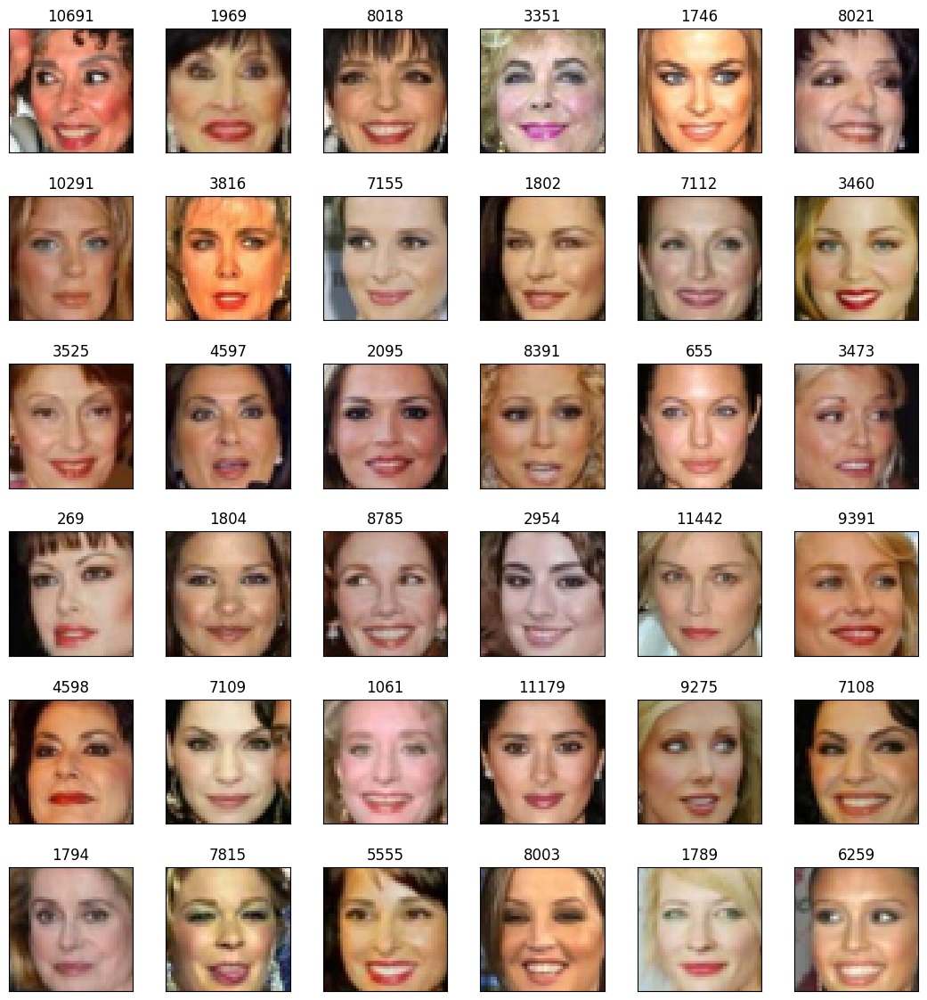

In [26]:
plot_gallery(makeup_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=makeup_ids)

### Constructing the encoder

Recall that the encoder part of the VAE architecture maps a data point to a variational mean and (log) variance. The mean is a point in the latent space.


In [27]:
LATENT_SPACE_SIZE = 100

The "reparameterization trick" draws samples from the variational distribution that are parameterized by the variational mean and variance, so that the parameters of the encoder network can be trained.


In [28]:
def sample_latent_features(distribution):
    distribution_mean, distribution_variance = distribution
    batch_size = tensorflow.shape(distribution_variance)[0]
    random = tensorflow.keras.backend.random_normal(shape=(batch_size, tensorflow.shape(distribution_variance)[1]))
    return distribution_mean + tensorflow.exp(0.5 * distribution_variance) * random

In [29]:
input_data = tensorflow.keras.layers.Input(shape=(45, 45, 3))

encoder = tensorflow.keras.layers.Conv2D(64, (5,5), activation='relu')(input_data)
encoder = tensorflow.keras.layers.MaxPooling2D((2,2))(encoder)

encoder = tensorflow.keras.layers.Conv2D(64, (3,3), activation='relu')(encoder)
encoder = tensorflow.keras.layers.MaxPooling2D((2,2))(encoder)

encoder = tensorflow.keras.layers.Conv2D(32, (3,3), activation='relu')(encoder)
encoder = tensorflow.keras.layers.MaxPooling2D((2,2))(encoder)

encoder = tensorflow.keras.layers.Flatten()(encoder)

distribution_mean = tensorflow.keras.layers.Dense(LATENT_SPACE_SIZE, name='variational_mean')(encoder)
distribution_variance = tensorflow.keras.layers.Dense(LATENT_SPACE_SIZE, name='variational_log_variance')(encoder)
latent_encoding = tensorflow.keras.layers.Lambda(sample_latent_features)([distribution_mean, distribution_variance])

encoder_model = tensorflow.keras.Model(input_data, latent_encoding)
encoder_model.summary()

2025-10-20 21:17:31.253453: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-10-20 21:17:31.253539: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-10-20 21:17:31.253613: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-10-20 21:17:31.253692: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-10-20 21:17:31.253728: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 45, 45, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 41, 41,    │      4,864 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 20, 20,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 18, 18,    │     36,928 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 9, 9, 64)  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 7, 7, 32)  │     18,464 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 3, 3, 32)  │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 288)       │          0 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ variational_mean    │ (None, 100)       │     28,900 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ variational_log_va… │ (None, 100)       │     28,900 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 100)       │          0 │ variational_mean… │
│                     │                   │            │ variational_log_… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 118,056 (461.16 KB)

 Trainable params: 118,056 (461.16 KB)

 Non-trainable params: 0 (0.00 B)

### Construct the decoder

The decoder network in the VAE architecture maps a latent vector to an image.
This is done with a series of transposed convolutional layers, since it must
map from low to high dimensions.


In [30]:
decoder_input = tensorflow.keras.layers.Input(shape=(LATENT_SPACE_SIZE,))
decoder = tensorflow.keras.layers.Reshape((1, 1, 100))(decoder_input)
decoder = tensorflow.keras.layers.Conv2DTranspose(64, (3,3), activation='relu')(decoder)
decoder = tensorflow.keras.layers.UpSampling2D((2,2))(decoder)

decoder = tensorflow.keras.layers.Conv2DTranspose(32, (3,3), activation='relu')(decoder)
decoder = tensorflow.keras.layers.UpSampling2D((2,2))(decoder)

decoder = tensorflow.keras.layers.Conv2DTranspose(16, (5,5), activation='relu')(decoder)
decoder = tensorflow.keras.layers.UpSampling2D((2,2))(decoder)

decoder_output = tensorflow.keras.layers.Conv2DTranspose(3, (6,6), activation='relu')(decoder)

decoder_model = tensorflow.keras.Model(decoder_input, decoder_output)
decoder_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 1, 1, 100)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 3, 3, 64)       │        57,664 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 8, 8, 32)       │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 20, 20, 16)     │        12,816 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 40, 40, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 45, 45, 3)      │         1,731 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,675 (354.20 KB)

 Trainable params: 90,675 (354.20 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
encoded = encoder_model(input_data)
decoded = decoder_model(encoded)
autoencoder = tensorflow.keras.models.Model(input_data, decoded)

In [32]:
def get_loss(distribution_mean, distribution_variance, factor, batch_size):

    def get_reconstruction_loss(y_true, y_pred, factor, batch_size):
        reconstruction_loss = tensorflow.math.squared_difference(y_true, y_pred)
        reconstruction_loss_batch = tensorflow.reduce_sum(reconstruction_loss)/batch_size
        return 0.5*reconstruction_loss_batch*factor

    def get_kl_loss(distribution_mean, distribution_variance, batch_size):
        kl_loss = LATENT_SPACE_SIZE + distribution_variance - tensorflow.square(distribution_mean) - tensorflow.exp(distribution_variance)
        kl_loss_batch = tensorflow.reduce_sum(kl_loss)/batch_size
        return kl_loss_batch*(-0.5)

    def total_loss(y_true, y_pred):
        reconstruction_loss_batch = get_reconstruction_loss(y_true, y_pred, factor, batch_size)
        kl_loss_batch = get_kl_loss(distribution_mean, distribution_variance, batch_size)
        return reconstruction_loss_batch + kl_loss_batch

    return total_loss

In [33]:
from keras import ops, layers, Model
from keras.losses import mean_squared_error as mse

# --- KL layer ---
class KLLoss(layers.Layer):
    def call(self, inputs):
        mu, logvar = inputs
        # KL per sample: -0.5 * sum(1 + logvar - mu^2 - exp(logvar))
        kl_per_sample = -0.5 * ops.sum(1.0 + logvar - ops.square(mu) - ops.exp(logvar), axis=-1)
        self.add_loss(ops.mean(kl_per_sample))  # scalar KL
        return inputs  # pass-through

# 1) Create the KL node
kl_node = KLLoss(name="kl_loss")([distribution_mean, distribution_variance])

# 2) Tie the KL node into the forward graph but keep output = decoded
decoded = layers.Lambda(lambda xs: xs[0], name="with_kl")([decoded, kl_node])

# 3) (Re)build the model so the KL loss is included
autoencoder = tensorflow.keras.models.Model(input_data, decoded, name="autoencoder_with_kl")

# 4) reconstruction loss
def reconstruction_loss(y_true, y_pred, sum_over_channels=False):
    # per-pixel MSE (averaged over channels)
    per_pixel = mse(y_true, y_pred)                 # (B, H, W)
    H = ops.shape(per_pixel)[1]
    W = ops.shape(per_pixel)[2]
    factor = ops.cast(H * W, per_pixel.dtype)
    if sum_over_channels:
        C = ops.shape(y_true)[-1]                   # undo the channel mean
        factor = factor * ops.cast(C, per_pixel.dtype)
    return ops.mean(per_pixel) * factor             # mean over batch, sum over chosen dims

### 1.1 Deriving the loss function (5 points)

Derive the loss function defined in the cell above from the probability model perspective. You can ignore the scalar `factor` in your derivation. Show your work using either LaTeX or a picture of your written solution.

Hint: Think about how how the total loss is related to the ELBO.

[Your derivation here]

#### Derivation of the KL term
$$
D_{\mathrm{KL}}(q \,\|\, p)
= \int q(z) \log \frac{q(z)}{p(z)} \, dz
= \mathbb{E}_{z \sim q} \left[ \log q(z) - \log p(z) \right].
$$

Distributions
$$
q_\phi(z \mid x)
= \mathcal{N}\big(z;\ \mu,\ \mathrm{diag}(\sigma^2)\big),
\quad
p(z)
= \mathcal{N}(z;\ 0,\ I),
$$

where $\mu = (\mu_1,\dots,\mu_d)$ and $\sigma^2 = (\sigma_1^2,\dots,\sigma_d^2)$.

Log of q
$$
\log q_\phi(z \mid x)
=
-\frac{1}{2}
\sum_{j=1}^{d}
\left[
\log (2\pi \sigma_j^2)
+
\frac{(z_j - \mu_j)^2}{\sigma_j^2}
\right].
$$

Log of p
$$
\log p(z)
=
-\frac{1}{2}
\sum_{j=1}^{d}
\left[
\log (2\pi)
+
z_j^2
\right].
$$

Plug in to KL definition
$$
D_{\mathrm{KL}}\big(q_\phi(z \mid x) \,\|\, p(z)\big)
=
\mathbb{E}_{z \sim q_\phi}
\left[
\log q_\phi(z \mid x) - \log p(z)
\right].
$$

Therefore,

$$
D_{\mathrm{KL}}
=
\mathbb{E}_{z \sim q_\phi}
\left[
-\frac{1}{2}
\sum_{j=1}^{d}
\left(
\log (2\pi \sigma_j^2)
+
\frac{(z_j - \mu_j)^2}{\sigma_j^2}
\right)
+
\frac{1}{2}
\sum_{j=1}^{d}
\left(
\log (2\pi)
+
z_j^2
\right)
\right].
$$

Bring the sums together:

$$
D_{\mathrm{KL}}
=
\frac{1}{2}
\sum_{j=1}^{d}
\mathbb{E}_{z \sim q_\phi}
\left[
-\log (2\pi \sigma_j^2)
-
\frac{(z_j - \mu_j)^2}{\sigma_j^2}
+
\log (2\pi)
+
z_j^2
\right].
$$

Simplify the log terms using
$$
-\log(2\pi \sigma_j^2) + \log(2\pi)
= -\log(\sigma_j^2),
$$

to get

$$
D_{\mathrm{KL}}
=
\frac{1}{2}
\sum_{j=1}^{d}
\mathbb{E}_{z \sim q_\phi}
\left[
-\log (\sigma_j^2)
-
\frac{(z_j - \mu_j)^2}{\sigma_j^2}
+
z_j^2
\right].
$$

Now take expectations term by term under $z_j \sim \mathcal{N}(\mu_j, \sigma_j^2)$.

We use:
$$
\mathbb{E}[z_j] = \mu_j,
\quad
\mathbb{E}[z_j^2] = \mu_j^2 + \sigma_j^2,
\quad
\mathbb{E}[(z_j - \mu_j)^2] = \sigma_j^2.
$$

1. Constant term:
$$
\mathbb{E}_{z \sim q_\phi} \left[ -\log(\sigma_j^2) \right]
= -\log(\sigma_j^2).
$$

2. Quadratic around the mean:
$$
\mathbb{E}_{z \sim q_\phi} \left[ \frac{(z_j - \mu_j)^2}{\sigma_j^2} \right]
=
\frac{ \mathbb{E}[(z_j - \mu_j)^2] }{\sigma_j^2}
=
\frac{\sigma_j^2}{\sigma_j^2}
= 1.
$$

So that contributes $-1$ because of the minus sign.

3. Second moment:
$$
\mathbb{E}_{z \sim q_\phi} \left[ z_j^2 \right]
=
\mu_j^2 + \sigma_j^2.
$$

Substitute these into the expectation:

$$
D_{\mathrm{KL}}
=
\frac{1}{2}
\sum_{j=1}^{d}
\left[
-\log(\sigma_j^2)
- 1
+ \mu_j^2
+ \sigma_j^2
\right].
$$



####  Derivation of the reconstruction / likelihood term in a VAE
Showing that MSE corresponds to negative log-likelihood under a Gaussian decoder

We assume the decoder defines $p_\theta(x | z)$ as an independent Gaussian with fixed variance $\sigma^2$ for every pixel (and channel).
Let $x \in \mathbb{R}^N$ be the observed data (e.g. an image flattened), and let $\mu_\theta(z) \in \mathbb{R}^N$ be the decoder's output given z.

Likelihood model:
$$
p_\theta(x \mid z)
=
\mathcal{N}\big(
x;\ \mu_\theta(z),\ \sigma^2 I
\big)
=
\prod_{i=1}^{N}
\mathcal{N}\big(
x_i;\ \mu_{\theta,i}(z),\ \sigma^2
\big).
$$

Write out one Gaussian factor:
$$
\mathcal{N}(x_i;\ \mu_{\theta,i}(z),\ \sigma^2)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{1}{2\sigma^2}
\big(x_i - \mu_{\theta,i}(z)\big)^2
\right).
$$

Therefore, the full likelihood is:
$$
p_\theta(x \mid z)
=
\prod_{i=1}^{N}
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{1}{2\sigma^2}
\big(x_i - \mu_{\theta,i}(z)\big)^2
\right).
$$

Take the log of both sides to get the log-likelihood:
$$
\log p_\theta(x \mid z)
=
\sum_{i=1}^{N}
\log
\left[
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{1}{2\sigma^2}
\big(x_i - \mu_{\theta,i}(z)\big)^2
\right)
\right].
$$

Split the log of a product into sum of logs, and the log of a product into sum:
$$
\log p_\theta(x \mid z)
=
\sum_{i=1}^{N}
\left[
-\frac{1}{2} \log(2\pi\sigma^2)
-\frac{1}{2\sigma^2}
\big(x_i - \mu_{\theta,i}(z)\big)^2
\right].
$$

Separate constant and quadratic terms:
$$
\log p_\theta(x \mid z)
=
-\frac{N}{2} \log(2\pi\sigma^2)
-\frac{1}{2\sigma^2}
\sum_{i=1}^{N}
\big(x_i - \mu_{\theta,i}(z)\big)^2.
$$

Now take the negative log-likelihood (this is what we minimize in training):
$$
-\log p_\theta(x \mid z)
=
\frac{1}{2\sigma^2}
\sum_{i=1}^{N}
\big(x_i - \mu_{\theta,i}(z)\big)^2
+
\frac{N}{2} \log(2\pi\sigma^2).
$$

The second term, $\frac{N}{2}\log(2\pi\sigma^2)$, does not depend on the network outputs $\mu_{\theta}(z)$ if $\sigma^2$ is fixed. So for optimization it is just a constant offset.

So, up to an additive constant and a fixed scalar factor $1/(2\sigma^2)$, minimizing negative log-likelihood is equivalent to minimizing squared error:
$$
-\log p_\theta(x \mid z)
\;\propto\;
\sum_{i=1}^{N}
\big(x_i - \mu_{\theta,i}(z)\big)^2.
$$


If we define the per-pixel MSE as
$$
\text{MSE}(x, \mu_\theta(z))
=
\frac{1}{N}
\sum_{i=1}^{N}
\big(x_i - \mu_{\theta,i}(z)\big)^2,
$$

then the squared-error term can be written as
$$
\sum_{i=1}^{N}
\big(x_i - \mu_{\theta,i}(z)\big)^2
=
N \cdot \text{MSE}(x, \mu_\theta(z)).
$$

Putting this back: Up to a constant term (which doesn't affect gradients) and a constant scale, the negative log-likelihood is proportional to MSE:
$$
-\log p_\theta(x \mid z)
\;\propto\;
\text{MSE}(x, \mu_\theta(z)).
$$

Therefore: The "reconstruction loss" used in code, which is basically mean squared error between the decoder output and the input, is exactly the negative log-likelihood of the data under an isotropic Gaussian observation model with fixed variance.


The following three cells train the model. You can just run them. It may take a while to run on your laptop.

In [34]:
X_train, X_val = train_test_split(data, test_size=0.2, random_state=365)

In [35]:
batch_size = 64
# autoencoder.compile(loss=get_loss(distribution_mean, distribution_variance, factor = 100,
#                                   batch_size = batch_size), optimizer='adam')
autoencoder.compile(optimizer="adam", loss=reconstruction_loss)

autoencoder.summary()

Model: "autoencoder_with_kl"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 45, 45, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 41, 41,    │      4,864 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 20, 20,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 18, 18,    │     36,928 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 9, 9, 64)  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 7, 7, 32)  │     18,464 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 3, 3, 32)  │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 288)       │          0 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ (None, 100)       │    118,056 │ input_layer[0][0] │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ variational_mean    │ (None, 100)       │     28,900 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ variational_log_va… │ (None, 100)       │     28,900 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_1        │ (None, 45, 45, 3) │     90,675 │ functional[0][0]  │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ kl_loss (KLLoss)    │ [(None, 100),     │          0 │ variational_mean… │
│                     │ (None, 100)]      │            │ variational_log_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ with_kl (Lambda)    │ (None, 45, 45, 3) │          0 │ functional_1[0][… │
│                     │                   │            │ kl_loss[0][0],    │
│                     │                   │            │ kl_loss[0][1]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 208,731 (815.36 KB)

 Trainable params: 208,731 (815.36 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
autoencoder.fit(X_train, X_train, epochs=50, batch_size=64, validation_data=(X_val, X_val))

Epoch 1/50


2025-10-20 21:20:15.915361: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


165/165 ━━━━━━━━━━━━━━━━━━━━ 65s 355ms/step - loss: 97.6564 - val_loss: 58.3382
Epoch 2/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 56s 341ms/step - loss: 49.2681 - val_loss: 43.8752
Epoch 3/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 56s 342ms/step - loss: 41.6257 - val_loss: 38.9695
Epoch 4/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 57s 345ms/step - loss: 37.7004 - val_loss: 35.8306
Epoch 5/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 57s 343ms/step - loss: 35.2383 - val_loss: 33.9579
Epoch 6/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 56s 341ms/step - loss: 33.5605 - val_loss: 32.5776
Epoch 7/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 56s 341ms/step - loss: 32.2439 - val_loss: 31.1773
Epoch 8/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 57s 343ms/step - loss: 31.1614 - val_loss: 30.4436
Epoch 9/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 56s 342ms/step - loss: 30.4851 - val_loss: 30.3495
Epoch 10/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 57s 347ms/step - loss: 29.8231 - val_loss: 30.2840
Epoch 11/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 57s 343ms/step - loss: 29.1436 - val_loss: 28.5536
Epoch 12

In [40]:
# Save your trained model (for later use)

autoencoder.save("/Users/yingxuanyang/Library/CloudStorage/Dropbox/Mac/Documents/GitHub/SDS365_Assignments/assignments/assn3/My_Trained_VAE.keras")
encoder_model.save("/Users/yingxuanyang/Library/CloudStorage/Dropbox/Mac/Documents/GitHub/SDS365_Assignments/assignments/assn3/My_Trained_encoder.keras")
decoder_model.save("/Users/yingxuanyang/Library/CloudStorage/Dropbox/Mac/Documents/GitHub/SDS365_Assignments/assignments/assn3/My_Trained_decoder.keras")

If you experience issues while training the models above or if the process is taking too long, you may also use our pre-trained versions of the VAE, encoder, and decoder, which are available on Canvas.

No points will be taken off if you decide to use the pre-trained models, but we do recommend trying out the training process above. In case you encounter any issues when loading in the models, please post your questions on Ed discussion.

In [ ]:
# Load Pre-trained Model

# batch_size = 64
# autoencoder = tensorflow.keras.models.load_model("Trained_VAE",compile=False)
# autoencoder.compile(loss=get_loss(distribution_mean, distribution_variance, factor = 100, batch_size = batch_size), optimizer='Adam')

# encoder_model = tensorflow.keras.models.load_model("Trained_encoder",compile=False)
# encoder_model.compile(loss=get_loss(distribution_mean, distribution_variance, factor = 100, batch_size = batch_size), optimizer='Adam')

# decoder_model = tensorflow.keras.models.load_model("Trained_decoder",compile=False)
# decoder_model.compile(loss=get_loss(distribution_mean, distribution_variance, factor = 100, batch_size = batch_size), optimizer='Adam')

### 1.2 Reconstructing faces (3 points)

The following cell encodes and reconstructs 16 random faces from the validation set with the trained VAE. Run the cell and comment on the reconstructed faces. (3 points)
* Do the reconstructed faces resemble the original images? How are they similar/different?
* Are there any faces that are reconstructed better or worse than the others? Can you think of why?
* Comment on any other aspects of your findings that are interesting to you.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


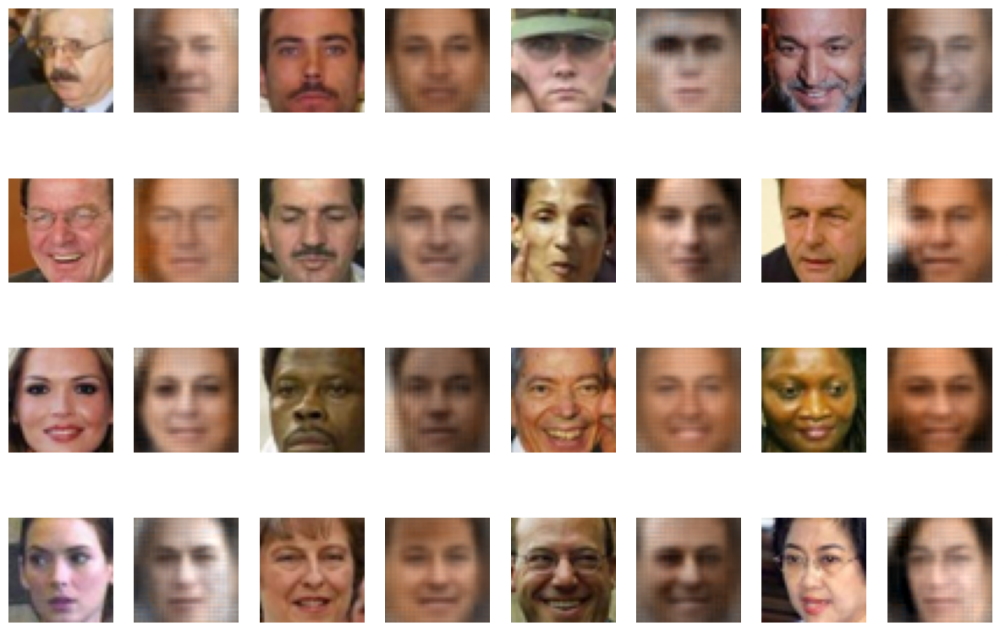

In [44]:
sample_index = random.sample(range(1, len(X_val)), 16)

fig, axs = plt.subplots(4, 8)
fig.set_figheight(10)
fig.set_figwidth(15)

for i in range(4):
    for j in range(4):
        axs[i, 2*j].imshow(X_val[sample_index[4*i+j], :, :, :])
        axs[i, 2*j].axis('off')
        axs[i, 2*j+1].imshow(np.clip(autoencoder.predict(np.array([X_val[sample_index[4*i+j], :, :, :]]))[0],0,1))
        axs[i, 2*j+1].axis('off')

[Your markdown here]

1. Do the reconstructed faces resemble the original images? How are they similar/different?

In general: yes, but not perfectly. Head shape, pose (facing left/right/center), hair silhouette, background tone, and rough skin tone usually match. Location of eyes / nose / mouth, presence of glasses or facial hair, sometimes hairstyle match. However, eyes tend to get blurry, teeth smear into a white patch, hair strands become a fuzzy blob.

2. Are there any faces that are reconstructed better or worse than the others? Can you think of why?
Better reconstructions: Frontal faces with neutral lighting and no extreme expression; Faces that look “typical” compared to the training data (average skin tone, no unusual occlusions); Smooth regions (cheeks, forehead) and large color areas (backgrounds, shirts) get captured well.

Those are easy for a low-dimensional latent code to summarize. The decoder can map that latent back to something very close because it's seen tons of similar examples.

3. Comment on any other aspects of your findings that are interesting to you.
Even though details are smoothed, you usually can still pair each original with its reconstruction and tell it's the same source image. That means the latent still carries meaningful identity-level info.

### 1.3 Visualizing the latent space (10 points)

In `vae_demo` from class, the MNIST digits were generated from a two-dimensional latent space. In the current model, the latent space has more than two dimensions, so to visualize it we need to use a dimensionality reduction technique. (If you are not familiar with PCA, please refer to the material for Week 7 of [iML](https://ydata123.org/fa21/iml/calendar.html).)

In this problem, you will first implement the function `LatentSpace_2D`. (6 points)
1. Calculate the latent space encodings for two sets of faces that are different in one attribute, e.g. smile vs. no smile.
2. Use PCA to reduce the dimension of the latent space codes to two.
3. Visualize the latent space after dimensionality reduction with a scatter plot. Clearly color-code and label the two different groups.

Here is an example using smile_data and no_smile_data.
![Sample_1_3](https://raw.githubusercontent.com/YData123/sds365-sp22/main/assignments/assn3/Sample_1_3.png)

Visualize the latent space for at least three pairs of face groups including smile vs. no smile. Comment on how the scatter plots look.
* Are the two groups separable in the two-dimensional latent space? Is this what you expected? Why or why not? (2 points)
* How do the plots for the three different attributes differ from each other? (2 points)

In [50]:
encoder_mean_model = tensorflow.keras.Model(input_data, distribution_mean)
encoder_mean_model.summary()

def LatentSpace_2D(encoder_mean_model, data1, label1, data2, label2):
    # 1. Get latent means for both groups
    enc1 = encoder_mean_model.predict(data1)  # shape (N1, latent_dim)
    enc2 = encoder_mean_model.predict(data2)  # shape (N2, latent_dim)

    # 2. Stack and PCA to 2D
    Z_all = np.vstack([enc1, enc2])
    pca = PCA(n_components=2)
    Z_2D = pca.fit_transform(Z_all)

    # 3. Split back
    Z1_2D = Z_2D[:len(enc1)]
    Z2_2D = Z_2D[len(enc1):]

    # 4. Plot
    plt.figure(figsize=(6,5))
    plt.scatter(Z1_2D[:,0], Z1_2D[:,1], alpha=0.6, label=label1)
    plt.scatter(Z2_2D[:,0], Z2_2D[:,1], alpha=0.6, label=label2)
    plt.xlabel('PC 1')
    plt.ylabel('PC 2')
    plt.title(f'Latent space (PCA → 2D): {label1} vs {label2}')
    plt.legend()
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

    return Z1_2D, Z2_2D


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 45, 45, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 41, 41, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 18, 18, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 9, 9, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 32)       │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ variational_mean (Dense)        │ (None, 100)            │        28,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,156 (348.27 KB)

 Trainable params: 89,156 (348.27 KB)

 Non-trainable params: 0 (0.00 B)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


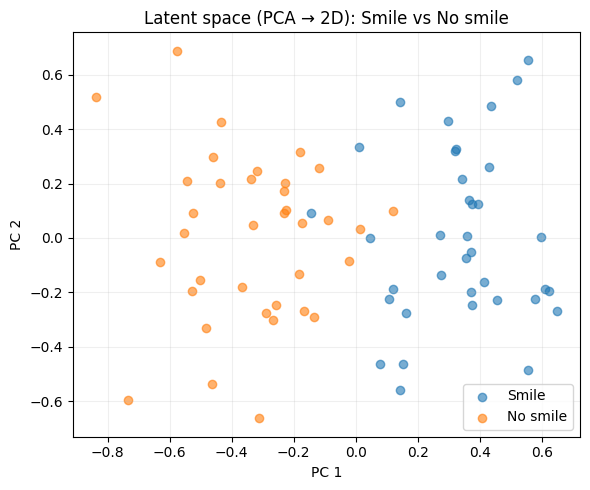

(array([[ 0.578652  , -0.22266656],
        [ 0.07704491, -0.46504092],
        [ 0.6485595 , -0.26779872],
        [ 0.1425275 , -0.55947894],
        [ 0.60980785, -0.18570028],
        [ 0.36602953,  0.1408532 ],
        [ 0.14290556,  0.49911547],
        [ 0.3191255 ,  0.3192999 ],
        [-0.1436222 ,  0.09237026],
        [ 0.4137087 , -0.16282488],
        [ 0.43651953,  0.48647994],
        [ 0.520357  ,  0.5803997 ],
        [ 0.42875472,  0.25960773],
        [ 0.37271523, -0.05332194],
        [ 0.32352465,  0.32673234],
        [ 0.11888722, -0.18746789],
        [ 0.39411798,  0.1238333 ],
        [ 0.55602723,  0.65418774],
        [ 0.374723  ,  0.12671468],
        [ 0.623337  , -0.19489035],
        [ 0.2719151 ,  0.00948885],
        [ 0.59570444,  0.00481438],
        [ 0.45647812, -0.22708179],
        [ 0.5559774 , -0.4839297 ],
        [ 0.10658149, -0.22389139],
        [ 0.27426648, -0.13608754],
        [ 0.3569257 , -0.07456015],
        [ 0.15127209, -0.462

In [51]:
LatentSpace_2D(encoder_mean_model, smile_data, 'Smile', no_smile_data, 'No smile')

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


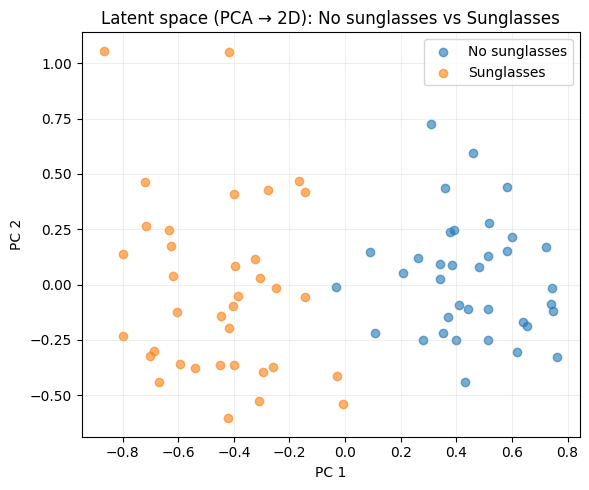

(array([[ 0.5836931 ,  0.44150913],
        [ 0.43008408, -0.43968436],
        [ 0.7239016 ,  0.17061478],
        [ 0.61819607, -0.3041367 ],
        [ 0.7393336 , -0.08667576],
        [ 0.5169518 ,  0.27879465],
        [ 0.08864824,  0.14632595],
        [ 0.34302285,  0.02450496],
        [ 0.10751724, -0.21760136],
        [ 0.3843844 ,  0.08837882],
        [ 0.7631484 , -0.32680795],
        [ 0.309783  ,  0.7257102 ],
        [ 0.3402111 ,  0.09362023],
        [ 0.5838866 ,  0.1494176 ],
        [ 0.7491807 , -0.11759777],
        [ 0.2095454 ,  0.05010927],
        [ 0.65410745, -0.1890408 ],
        [ 0.3593611 ,  0.43666077],
        [ 0.51441437, -0.11173059],
        [ 0.59874916,  0.21558832],
        [ 0.4408509 , -0.10836768],
        [ 0.4596048 ,  0.5934694 ],
        [ 0.63833946, -0.16945332],
        [ 0.74350876, -0.01536109],
        [ 0.27892318, -0.25125614],
        [ 0.5129578 , -0.25056022],
        [ 0.37727696,  0.23866056],
        [ 0.4079516 , -0.093

In [52]:
LatentSpace_2D(encoder_mean_model,smile_data,'No sunglasses',sunglasses_data,'Sunglasses')

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


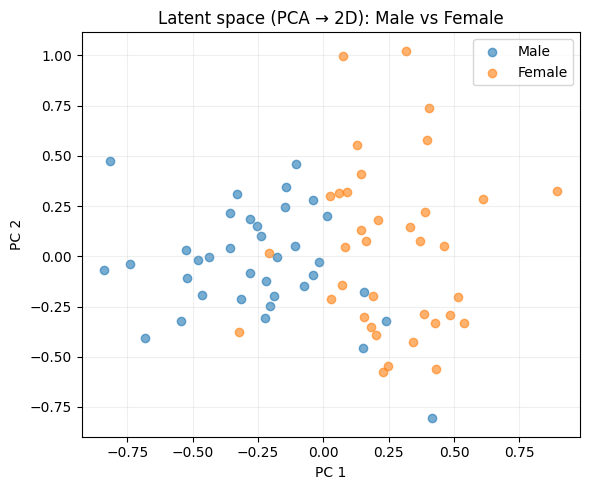

(array([[-0.35916546,  0.04053557],
        [-0.14654317,  0.24347259],
        [-0.07599118, -0.14747597],
        [-0.74099773, -0.03789819],
        [-0.838786  , -0.06975784],
        [-0.04151123,  0.28165555],
        [-0.81724745,  0.47520763],
        [-0.04092241, -0.09509097],
        [-0.3288566 ,  0.31191382],
        [-0.68443817, -0.40591556],
        [ 0.15602106, -0.17507839],
        [-0.22368081, -0.3086334 ],
        [-0.10552226,  0.46051615],
        [-0.2552234 ,  0.1524291 ],
        [-0.52456266,  0.03068946],
        [-0.48015723, -0.02058113],
        [-0.5215199 , -0.10834295],
        [ 0.01425005,  0.20234425],
        [-0.10901493,  0.04974521],
        [-0.46435297, -0.19133028],
        [-0.54609585, -0.3207669 ],
        [-0.01752304, -0.02652553],
        [ 0.1529945 , -0.45422736],
        [ 0.4139883 , -0.8064821 ],
        [-0.28123277,  0.18502243],
        [-0.17742515, -0.00524309],
        [ 0.24007025, -0.3230571 ],
        [-0.19058798, -0.198

In [53]:
LatentSpace_2D(encoder_mean_model,male_data,'Male',female_data,'Female')

[Your markdown here]

1. Are the two groups separable in the two-dimensional latent space? Is this what you expected? Why or why not?

Smile vs. No smile
The two groups are partly separated along PC1: most of the “Smile” points (blue) live on the right side of the plot, while most of the “No smile” points (orange) live toward the left. But there’s still some overlap in the middle region. So they’re not perfectly linearly separable, but there is a visible directional shift.

No sunglasses vs. Sunglasses 
These two groups are much more cleanly separated. The “Sunglasses” cluster (orange) sits mainly on the left side in PC1, and the “No sunglasses” cluster (blue) sits on the right. There’s very little overlap. This basically looks like two distinct blobs.

Male vs. Female 
There’s some structure: the “Male” points (blue) lean toward lower PC1 values and the “Female” points (orange) lean toward higher PC1 values. But compared to sunglasses, the clusters bleed into each other much more. They’re not cleanly split; there’s a big overlap band in the center.

Is this expected?
Yes. The VAE encoder wasn’t explicitly trained to classify any of these attributes. It was trained to compress whatever visual information is useful to reconstruct the whole face. After that, we did PCA, which only keeps the top two axes of variance in the latent codes.


2. How do the plots for the three different attributes differ from each other?

Sunglasses vs. no sunglasses: almost two separate islands → attribute is visually strong and consistent.

Smile vs. no smile: somewhat separated but still mixed → attribute is present, but weaker and partially entangled.

Male vs. female: partially separated but clearly overlapping → attribute is more diffuse, many visual factors, not a single “on/off” feature.

That pattern matches what we’d expect from a VAE’s latent space + PCA: attributes that cause a bold, localized, high-contrast change (like sunglasses) pop out most cleanly in 2D; more subtle or socially defined attributes don’t separate as cleanly.

### 1.4 Morphing between faces (4 points)

Morph at least 5 pairs of faces with the function `morphBetweenImages` and comment on what you observe.
* Briefly explain how the morphing works. (2 points)
* Do the generated faces look like what you expected? Does any of the pairs work better than the others? If so, what kind of image pairs work better? (2 points)

In [54]:
# Don't change the function
def morphBetweenImages(img1, img2, num_of_morphs):
    alpha = np.linspace(0,1,num_of_morphs)
    z1 = encoder_model.predict(np.array([img1]))
    z2 = encoder_model.predict(np.array([img2]))
    fig = plt.figure(figsize=(30,5))

    ax = fig.add_subplot(1, num_of_morphs+2, 1)
    ax.imshow(img1)
    ax.axis('off')
    ax.set_title(loc='center', label='original image 1',fontsize=10)

    for i in range(num_of_morphs):
        z = z1*(1-alpha[i]) + z2*alpha[i]
        new_img = decoder_model.predict(z)

        ax = fig.add_subplot(1, num_of_morphs+2, i+2)
        ax.imshow(np.clip(new_img.squeeze(),0,1))
        ax.axis('off')
        ax.set_title(loc='center', label='alpha={:.2f}'.format(alpha[i]))

    ax = fig.add_subplot(1, num_of_morphs+2, num_of_morphs+2)
    ax.imshow(img2)
    ax.axis('off')
    ax.set_title(loc='center', label='original image 2',fontsize=10)
    return

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


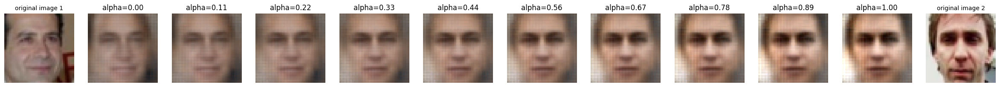

In [55]:
sample_index = random.sample(range(1, len(data)), 2)
morphBetweenImages(data[sample_index[0]],data[sample_index[1]],10)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


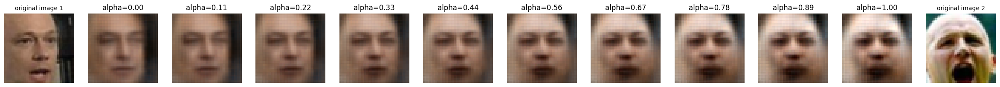

In [56]:
sample_index = random.sample(range(1, len(data)), 2)
morphBetweenImages(data[sample_index[0]],data[sample_index[1]],10)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


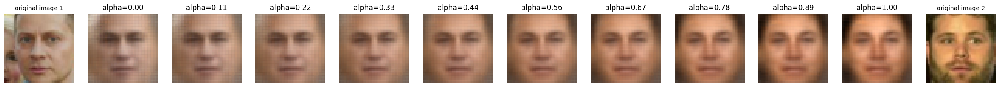

In [57]:
sample_index = random.sample(range(1, len(data)), 2)
morphBetweenImages(data[sample_index[0]],data[sample_index[1]],10)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


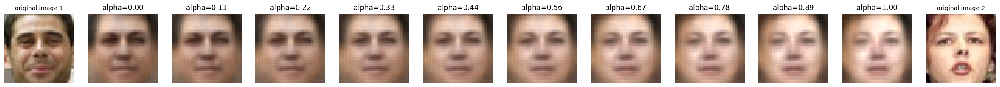

In [58]:
sample_index = random.sample(range(1, len(data)), 2)
morphBetweenImages(data[sample_index[0]],data[sample_index[1]],10)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


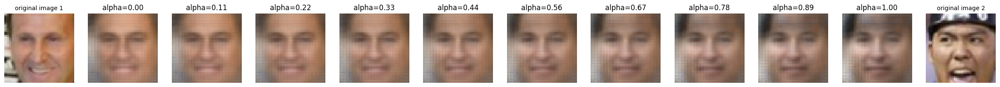

In [59]:
sample_index = random.sample(range(1, len(data)), 2)
morphBetweenImages(data[sample_index[0]],data[sample_index[1]],10)

1. Briefly explain how the morphing works. (2 points)

The function first encodes each of two images into their latent vectors using the encoder. It then linearly interpolates between those latent vectors: $z(\alpha)=(1-\alpha)z_1+\alpha z_2$ for $\alpha$ from $0$ to $1$. For each interpolated latent code, it uses the decoder to generate an image. Plotting those decoded images in order shows a smooth transition from face 1 to face 2. We are walking in the VAE’s latent space and decoding points along the line segment between the two faces.

2. Do the generated faces look like what you expected? Does any of the pairs work better than the others? If so, what kind of image pairs work better? (2 points)

Yes, they look like what I expected. The sequence of faces changes gradually: head shape, skin tone, hairstyle, and facial expression smoothly drift from the first person to the second. The intermediate faces generally still look like plausible faces, which suggests that the latent space learned by the VAE is fairly smooth and semantically organized.

In the first morph, the middle images look blurry and less realistic. The two source faces have different head orientations and strong but differently located mouth expressions, so the latent interpolation has to “average” incompatible geometry. The decoder can’t produce a coherent in-between pose, so midpoints look like melted faces rather than a smooth physical morph. This supports the idea that morphing works best for pairs with similar pose/structure, and breaks down when pose is very different.

The pairs that work better are the ones where the two faces are already pretty similar in their global geometry.

### 1.5 Attribute shift (10 points)

In 1.3, we've seen that faces with the same attributes form clusters in the latent space. In this problem, you will implement a function `AttributeShift` to change one attribute of the faces.

First implement the function `AttributeShift`. (5 points)
1. Calculate the latent space codes for two sets of faces that are different in one attribute, e.g. smile vs. no smile.
2. Calculate the mean latent space code for each group.
3. Get the attribute shifting vector by taking the difference between the two codes.
4. Perform attribute shift by adding the attribute shifting vector to the latent space code of the faces you want to modify.
5. Generate the image using the new latent space codes.

Here is a diagram demonstrating the shift in the latent space. Please note that the two-dimensional latent space is just for demonstration purpose. You should *not* use PCA in this problem. Instead, use the original latent space.
![Diagram_1_5](https://raw.githubusercontent.com/YData123/sds365-sp22/main/assignments/assn3/Diagram_1_5.png)

Perform attribute shift on at three attributes including smile. Comment on the faces with shifted attributes. (5 points)
* Do the generated faces look like what you expected? If not, can you think of some possible reasons?
* Do the faces with new attributes resemble the original faces? If not, can you think of some possible reasons?
* Which of the attribute shift is more successful? What are some possible reasons?
* Comment on any other aspects of your findings that are interesting to you.

In [71]:
# Don't change this helper function!
def PlotAttributeShift(data2,pic_output):
    sample_index = random.sample(range(1, len(data2)), 16)

    fig, axs = plt.subplots(4, 8)
    fig.set_figheight(10)
    fig.set_figwidth(15)

    for i in range(4):
        for j in range(4):
            axs[i, 2*j].imshow(data2[sample_index[4*i+j], :, :, :])
            axs[i, 2*j].axis('off')
            axs[i, 2*j+1].imshow(np.clip(pic_output[sample_index[4*i+j]],0,1))
            axs[i, 2*j+1].axis('off')

In [74]:
def AttributeShift(encoder_model,decoder_model,data1,data2):
    num_mc_samples=20
    # Helper: get a stable latent code by averaging multiple samples from encoder
    def encode_mean(model, batch):
        preds = []
        for _ in range(num_mc_samples):
            preds.append(model.predict(batch))        
        preds = np.stack(preds, axis=0)               
        return preds.mean(axis=0)                     
        
    z1_all = encode_mean(encoder_model, data1)         
    z2_all = encode_mean(encoder_model, data2)         

    z1_mean = np.mean(z1_all, axis=0, keepdims=True)  
    z2_mean = np.mean(z2_all, axis=0, keepdims=True)   

    shift_vec = z1_mean - z2_mean                       

    z2_shifted = z2_all + shift_vec                   

    pic_output = decoder_model.predict(z2_shifted)     

    return pic_output

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
2/2 ━━━━━━━━

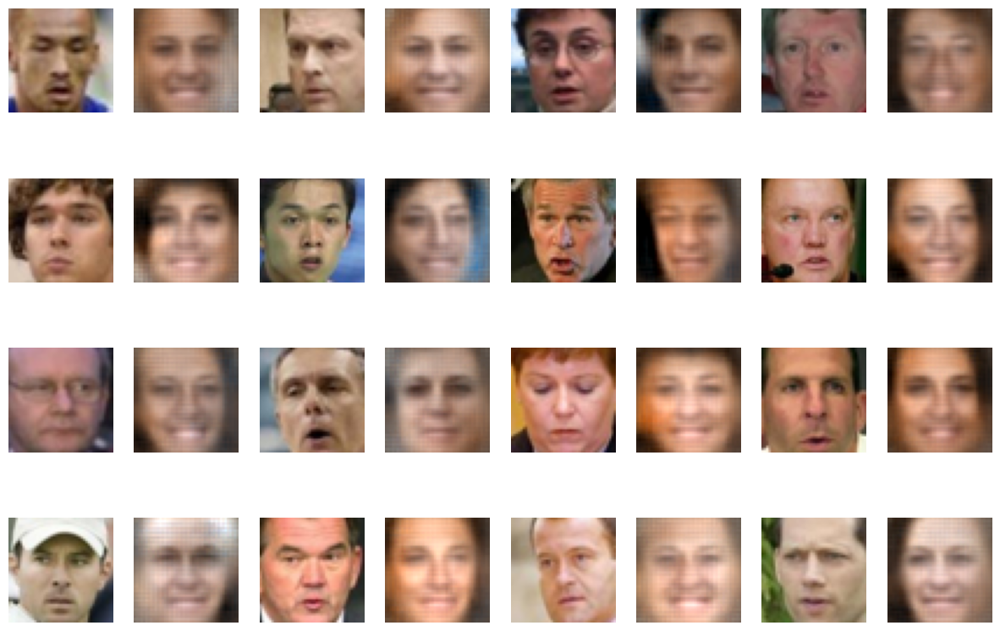

In [75]:
pic_output = AttributeShift(encoder_model,decoder_model,smile_data,no_smile_data)
PlotAttributeShift(no_smile_data,pic_output)

[Your markdown here]

When I add the smile vector, I don’t just get a mouth change; cheek shading, nasolabial area, and even skin tone/lighting drift a bit. That’s a sign the smile direction in latent space is entangled with correlated cues in the dataset (e.g., brighter lighting or slight head tilt when smiling).

### 1.6 Generating new faces (3 points)

Variational autoencoders can be used to generate new data; this is why they are generative models. We can sample new data points from the distribution in latent space and reconstruct new, fake faces based on them.

To draw a sample close to an existing sample in the latent space, we can add a scaled random sample from the normal distribution to the latent space code of an existing sample. The scalar, which we call the `noise_level` is a parameter that we can tune.

Run `GenerateFaces` with three different values of `noise_level` and comment on the generated faces. (3 points)
* Do the generated images look like faces?
* What happens when the new samples diverge more from the existing samples? What is a possible reason?

In [82]:
def GenerateFaces(data, LATENT_SPACE_SIZE, noise_level,number_of_images=5):
    sample_index = random.sample(range(1, len(data)), 15)
    latent_space = noise_level*np.random.normal(size=(15,LATENT_SPACE_SIZE))+encoder_model.predict(data[sample_index])
    generated_image = decoder_model.predict(latent_space)
    fig = plt.figure(figsize=(15,10))
    for i in range(number_of_images):
        ax = fig.add_subplot(3, 5, i+1)
        ax.imshow(np.clip(generated_image[i, :,:,:],0,1))
        ax.axis('off')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


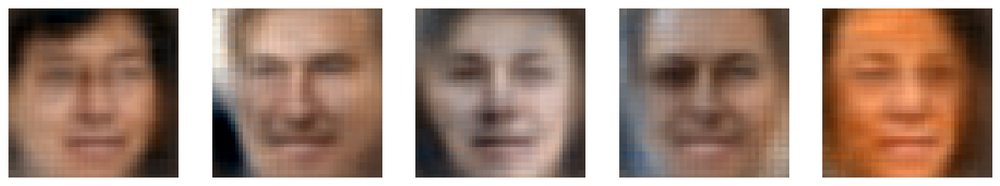

In [83]:
GenerateFaces(data,LATENT_SPACE_SIZE,0.1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


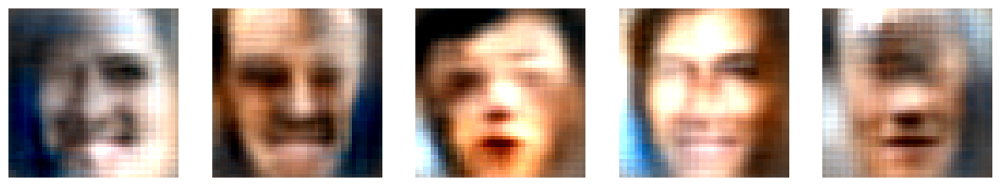

In [84]:
GenerateFaces(data,LATENT_SPACE_SIZE,0.5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


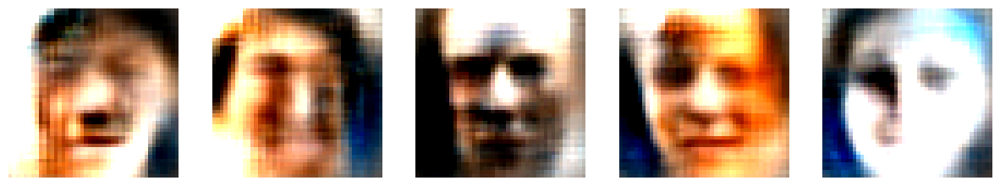

In [85]:
GenerateFaces(data,LATENT_SPACE_SIZE,1)

# Your markdown here
1. Do the generated images look like faces?

noise_level = 0.1: Mostly yes. The samples look like plausible faces—soft and a bit blurry, but with stable geometry (eyes/mouth in the right place).

noise_level = 0.5: Faces start to degrade. Some look okay, others show warped mouths/eyes and odd lighting patches. Still face-like, but artifacts are common.

noise_level = 1: Many outputs are no longer convincing faces—strong distortions, blown highlights, and “melty” features.

2. What happens when the new samples diverge more from the existing samples? What is a possible reason?

Increasing the noise pushes latent codes farther from the original point and, more importantly, off the learned face manifold. The decoder then has to decode latent points it never saw during training, so it hallucinates blurry or inconsistent structure (smears, misplaced features). 

### Optional: Changing the loss function (2 points extra credit)

The variable `factor` is a parameter of the loss function. In this optional problem, you will play with it and think about its effect on the performance of VAE.

Retrain the model with a smaller factor. Repeat 1.2, 1.6 (using `noise_level` = 1) and latent space visualization. Comment on how the reconstruction results, generated new faces and latent space distributions change. (2 points)
* Which model reconstructs the faces better?
* Do the generated faces look different?
* How do the latent variable distributions differ?
* Do the differences make sense? Can you explain what you observed?

In [ ]:
# Your code here

[Your markdown here]

## Problem 2: Gaussian neighborhood regression (10 points)
In multivariate Gaussians, edges are about *direct* relationships after controlling for all other variables. The conditional law of a single coordinate $X_i$ given the rest $X_{-i}$ reveals which variables directly “enter” the model for $X_i$. Algebraically, this local behavior is encoded by the $i$th row/column of the precision matrix $\Omega=\Sigma^{-1}$.  Graphical Lasso estimates a sparse precision matrix $\widehat{\Omega}$ by maximizing the Gaussian log-likelihood with an $\ell_1$ penalty on off-diagonal entries. Zeros in $\widehat{\Omega}$ correspond to missing edges (conditional independences) in the learned graph.



Let $X=(X_1,\dots,X_p)^\top \sim \mathcal N_p(0,\Sigma)$, and write $\Omega=\Sigma^{-1}$. For $i\in\{1,\dots,p\}$, denote $-i=\{1,\dots,p\}\setminus\{i\}$.




### 2.1 Conditional law of one node.
Show that $X_i\mid X_{-i}$ is Gaussian with a linear mean in $X_{-i}$. Express the regression coefficients $\beta_{i\leftarrow -i}\in\mathbb{R}^{p-1}$ and the conditional variance $\sigma^2_{i\mid -i}$ in terms of $\Omega$.


*Hint.* You may *complete the square* on $x^\top\Omega x$, or use a *Schur complement* derivation. After permuting coordinates so that $i$ is first, partition
$$
\Sigma \;=\; \begin{bmatrix}
a & b^\top \\[4pt]
b & C
\end{bmatrix},
\quad
a=\Sigma_{ii}\in\mathbb{R},\; b=\Sigma_{-i,i}\in\mathbb{R}^{p-1},\; C=\Sigma_{-i,-i}\in\mathbb{R}^{(p-1)\times(p-1)}.
$$
**Schur complement.** If $C$ is invertible (it is, since $\Sigma\succ 0$), the Schur complement of $C$ in $\Sigma$ is
$$
S \;:=\; a - b^\top C^{-1} b .
$$
**Block inversion formula.** Then
$$
\Sigma^{-1}
=\begin{bmatrix}
S^{-1} & -\,S^{-1} b^\top C^{-1}\\[4pt]
-\,C^{-1} b S^{-1} & C^{-1} + C^{-1} b S^{-1} b^\top C^{-1}
\end{bmatrix}.
$$

[Your markdown here]

By the standard conditional formula for Gaussians,
$$
X_i \mid X_{-i} 
\sim
\mathcal N\!\left(
b^\top C^{-1} x_{-i},
\;
a - b^\top C^{-1} b
\right).
$$

Define the regression coefficients $$\beta_{i \leftarrow -i} \in \mathbb{R}^{p-1}$$ and conditional variance $$\sigma^2_{i \mid -i}$$ by
$$
\mathbb{E}[X_i \mid X_{-i}] \;=\; \beta_{i \leftarrow -i}^\top X_{-i},
\qquad
\mathrm{Var}(X_i \mid X_{-i}) \;=\; \sigma^2_{i \mid -i}.
$$
From the above,
$$
\beta_{i \leftarrow -i}^\top = b^\top C^{-1},
\qquad
\sigma^2_{i \mid -i} = a - b^\top C^{-1} b.
$$

Now use the block inversion / Schur complement formula. We are given that
$$
\Sigma^{-1}
=
\begin{bmatrix}
S^{-1} & - S^{-1} b^\top C^{-1} \\
- C^{-1} b S^{-1} & C^{-1} + C^{-1} b S^{-1} b^\top C^{-1}
\end{bmatrix},
\qquad
S := a - b^\top C^{-1} b.
$$
We also write
$$
\Sigma^{-1}
=
\Omega
=
\begin{bmatrix}
\Omega_{ii} & \Omega_{i,-i}^\top \\
\Omega_{i,-i} & \Omega_{-i,-i}
\end{bmatrix}.
$$

By identifying blocks,
$$
\Omega_{ii} = S^{-1}
\quad\Longrightarrow\quad
S = \sigma^2_{i \mid -i} = \Omega_{ii}^{-1},
$$
and
$$
\Omega_{i,-i}^\top = - S^{-1} b^\top C^{-1}
\quad\Longrightarrow\quad
b^\top C^{-1}
= - \Omega_{ii}^{-1} \Omega_{i,-i}^\top.
$$

Therefore, in terms of the precision matrix $\Omega$
$$
\beta_{i \leftarrow -i}
= - \Omega_{ii}^{-1} \Omega_{i,-i},
$$
and
$$
\sigma^2_{i \mid -i} = \Omega_{ii}^{-1}.
$$

Thus,
$$
X_i \mid X_{-i}
\sim
\mathcal N\!\Big(
\beta_{i \leftarrow -i}^\top X_{-i},
\;
\sigma^2_{i \mid -i}
\Big),
\quad
\text{with }
\beta_{i \leftarrow -i}
= - \Omega_{ii}^{-1} \Omega_{i,-i},
\quad
\sigma^2_{i \mid -i}
= \Omega_{ii}^{-1}.
$$



### 2.2 One neighbor at a time.
Fix $j\neq i$. First prove that the coefficient of $X_j$ in the mean of $X_i \mid X_{-i}$ equals zero if and only if $\Omega_{ij}=0$. Then deduce (Gaussian case) that
$$\Omega_{ij}=0 \quad\Longleftrightarrow\quad X_i\ \perp\ X_j\ \big|\ X_{-(i,j)}.$$


*Hint:* Use the result from 2.1. *“iff” ($\Longleftrightarrow$) means:* prove **both** directions (⇒ and ⇐).  


[Your markdown here]

Fix $j \neq i$. Recall from 2.1 that
$$
X_i \mid X_{-i} \sim \mathcal N\!\Big( \beta_{i \leftarrow -i}^\top X_{-i}, \; \sigma^2_{i \mid -i} \Big),
$$
where
$$
\beta_{i \leftarrow -i} = - \Omega_{ii}^{-1} \Omega_{i,-i}
\qquad\text{and}\qquad
\sigma^2_{i \mid -i} = \Omega_{ii}^{-1}.
$$

Write $\beta_{i \leftarrow -i}$ componentwise as
$$
\beta_{i \leftarrow -i} = \big( \beta_{i \leftarrow 1}, \dots, \beta_{i \leftarrow (i-1)}, \beta_{i \leftarrow (i+1)}, \dots, \beta_{i \leftarrow p} \big)^\top,
$$
so that the conditional mean can be written explicitly as
$$
\mathbb{E}[X_i \mid X_{-i}] \;=\; \sum_{k \neq i} \beta_{i \leftarrow k} \, X_k.
$$

From the formula $\beta_{i \leftarrow -i} = - \Omega_{ii}^{-1} \Omega_{i,-i}$, we see that for each $j \neq i$,
$$
\beta_{i \leftarrow j}
\;=\;
- \Omega_{ii}^{-1} \, \Omega_{ij}.
$$

Because $\Omega_{ii}^{-1} > 0$ (since $\Omega \succ 0$), we have
$$
\beta_{i \leftarrow j} = 0
\quad\Longleftrightarrow\quad
\Omega_{ij} = 0.
$$

In words: the coefficient of $X_j$ in the conditional mean of $X_i \mid X_{-i}$ is zero if and only if $\Omega_{ij}=0$.


Now we prove the conditional independence statement for the Gaussian case:
$$
\Omega_{ij} = 0
\quad\Longleftrightarrow\quad
X_i \perp X_j \mid X_{-(i,j)}.
$$

($\Rightarrow$) Suppose $\Omega_{ij} = 0$. Then from above, $\beta_{i \leftarrow j} = 0$, so
$$
\mathbb{E}[X_i \mid X_{-i}]
=
\sum_{k \neq i,j} \beta_{i \leftarrow k} \, X_k
\quad\text{(no $X_j$ term).}
$$
Thus, conditioning on $X_{-(i,j)}$ already determines the conditional mean of $X_i$, and adding $X_j$ does not change it.

Moreover, from 2.1 the conditional variance
$$
\mathrm{Var}(X_i \mid X_{-i}) = \sigma^2_{i \mid -i} = \Omega_{ii}^{-1}
$$
is a constant (it does not depend on $X_{-i}$ at all), so in particular it also does not depend on $X_j$.

Therefore, the full conditional distribution of $X_i$ given $X_{-(i,j)}$ and $X_j$ does not actually depend on $X_j$. In other words,
$$
X_i \mid X_{-(i,j)}, X_j
\;\overset{d}{=}\;
X_i \mid X_{-(i,j)}.
$$
For jointly Gaussian vectors, this implies
$$
X_i \perp X_j \mid X_{-(i,j)}.
$$

($\Leftarrow$) Conversely, suppose
$$
X_i \perp X_j \mid X_{-(i,j)}.
$$
Then the conditional law of $X_i$ given $X_{-i}$ cannot depend on $X_j$. For a Gaussian, the only way this can happen is if the coefficient of $X_j$ in the conditional mean of $X_i \mid X_{-i}$ is zero. That is,
$$
\beta_{i \leftarrow j} = 0.
$$
From the expression $\beta_{i \leftarrow j} = - \Omega_{ii}^{-1} \Omega_{ij}$, this is equivalent to
$$
\Omega_{ij} = 0.
$$

Combining both directions, we conclude
$$
\Omega_{ij} = 0
\quad\Longleftrightarrow\quad
X_i \perp X_j \mid X_{-(i,j)}.
$$



### 2.3 Factorization and graph structure
Suppose every coefficient in the mean of $X_i\mid X_{-i}$ is zero (i.e., $\beta_{i\leftarrow -i}=0$). Show that the joint density factorizes as $p(x)=p(x_i)\,p(x_{-i})$. Briefly interpret the implication **for the graph structure**.

[Your markdown here]

Assume that every coefficient in the mean of $X_i \mid X_{-i}$ is zero. In the notation from 2.1,
$$
\mathbb{E}[X_i \mid X_{-i}] = \beta_{i \leftarrow -i}^\top X_{-i},
\qquad
\beta_{i \leftarrow -i} = - \Omega_{ii}^{-1} \Omega_{i,-i}.
$$
The assumption $\beta_{i \leftarrow -i} = 0$ means
$$
\beta_{i \leftarrow j} = 0 \quad \text{for all } j \neq i.
$$

From section 2.1, we also know
$$
X_i \mid X_{-i} \sim \mathcal N\!\Big( \beta_{i \leftarrow -i}^\top X_{-i},\; \sigma^2_{i \mid -i} \Big),
\qquad
\sigma^2_{i \mid -i} = \Omega_{ii}^{-1}.
$$

If $\beta_{i \leftarrow -i} = 0$, then
$$
X_i \mid X_{-i} \sim \mathcal N(0, \sigma^2_{i \mid -i}),
$$
and this conditional distribution does not depend on $X_{-i}$ at all (its mean is $0$, its variance is a constant).

Therefore,
$$
p(x_i \mid x_{-i}) = p(x_i).
$$
Multiplying both sides by $p(x_{-i})$ gives
$$
p(x_i, x_{-i}) = p(x_i \mid x_{-i}) \, p(x_{-i})
= p(x_i) \, p(x_{-i}).
$$

So the joint density factorizes as
$$
p(x) = p(x_i) \, p(x_{-i}).
$$

This factorization means that
$$
X_i \perp X_{-i},
$$
i.e. $X_i$ is independent of all other variables together.

Graph interpretation:
in a Gaussian graphical model, an edge between nodes $i$ and $j$ exists exactly when $\Omega_{ij} \neq 0$, which corresponds to $X_i$ and $X_j$ being not conditionally independent given the rest. From
$$
\beta_{i \leftarrow -i} = - \Omega_{ii}^{-1} \Omega_{i,-i},
$$
the condition $\beta_{i \leftarrow -i} = 0$ implies $\Omega_{i,-i} = 0$, i.e. all off-diagonal entries in row/column $i$ are zero. Thus node $i$ has no edges to any other node: it is completely disconnected (an isolated node) in the graph.


## Problem 3: Taking stock (15 points)

A joint distribution of data has a natural graph associated with it. When the distribution is multivariate normal, this graph is encoded in the pattern of zeros and non-zeros in the inverse of the covariance matrix, also known as the "precision matrix."

In class we demonstrated the graphical lasso for estimating the graph on ETF data.
In this problem you will construct two different "portfolios" of stocks,
and run the graphical lasso to estimate a graph, commenting on your results.

All of the code you might need for this is contained in the demo.


## Data provided

As demonstrated in class, you will run on equities data downloaded from Yahoo Finance. Your job is to construct two “portfolios” of stocks, each with some organizing principle (e.g., sectors, regions, indices vs. equities). Each portfolio must contain **at least 20 stocks**. The page https://en.wikipedia.org/wiki/List_of_S%26P_500_companies has GICS sectors, which you may find useful for the glasso problem.


You are provided two CSV files containing stock prices **since 2021-09-10 (post-COVID start)**:
- [full_stock_daily.csv](https://raw.githubusercontent.com/YData123/sds365-fa25/main/assignments/assn3/full_stock_daily.csv) (rows = dates, columns = **ticker** symbols; daily close)
- [full_stock_weekly.csv](https://raw.githubusercontent.com/YData123/sds365-fa25/main/assignments/assn3/full_stock_weekly.csv) (rows = dates, columns = **ticker** symbols; weekly close = last available trading day of the week)

> **Note on NAs.** Some symbols begin trading after 2021-09-10, so their early entries will be `NA`. Handle missingness during preprocessing (see checklist below).  

> You can look up prices by ticker and date directly from these CSVs. If a needed symbol is **not** in the CSVs, use the provided **R file** `stock_price_from_yahoo_finance.r` to fetch it (via BatchGetSymbols) and merge it into your working data.

**Preprocessing checklist (concise):**
- Select your symbols; **align dates** across symbols.
- For the analysis window you choose, **filter** symbols with poor coverage (e.g., keep ≥90–95% non-missing).
- Build a **complete-cases** matrix for Graphical Lasso (no NAs across chosen symbols/dates).

### Analyzing  your portfolios

Your task is to analyze each porfolio using the graphical lasso, and comment on your findings.
Here are the types of questions you should address:

* How did you choose the portolio? How did you choose the date range and frequency (daily, weekly, etc.)? Remember, each of the portfolios must contain at least 20 stocks, and be organized in some reasonable way.

* Display the graph obtained with the graphical lasso, using networkx. How did you choose the regularization level? Does the structure of the graph make sense? Is it sensitive to the choice of regularization level? Is this the structure you expected to see when you designed the portfolio? Why or why not?

* What are some of the conditional independence assumptions implied by the graph? Are some parts of the graph more densely connected than others? Why?




In [87]:
%pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 20.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


Portfolio A kept: 20 ['AAPL', 'MSFT', 'NVDA', 'AMD', 'INTC', 'AVGO', 'QCOM', 'TXN', 'ADI', 'MU', 'AMAT', 'LRCX', 'CRM', 'ORCL', 'NOW', 'META', 'GOOGL', 'AMZN', 'NFLX', 'TSLA']
Portfolio A dropped (coverage <95%): []
Portfolio B kept: 28 ['JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'PNC', 'USB', 'TFC', 'BK', 'SCHW', 'AXP', 'BLK', 'MMC', 'CB', 'AIG', 'MET', 'PRU', 'NEE', 'SO', 'DUK', 'D', 'AEP', 'EXC', 'XEL', 'SRE', 'PEG', 'ED']
Portfolio B dropped (coverage <95%): []
Chosen alpha (A): 0.0588
Chosen alpha (B): 0.0417


/Users/yingxuanyang/miniforge3/envs/tf-apple/lib/python3.11/site-packages/numpy/core/_methods.py:173: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)
/Users/yingxuanyang/miniforge3/envs/tf-apple/lib/python3.11/site-packages/sklearn/covariance/_graph_lasso.py:191: ConvergenceWarning: graphical_lasso: did not converge after 100 iteration: dual gap: 1.578e-03
  warnings.warn(


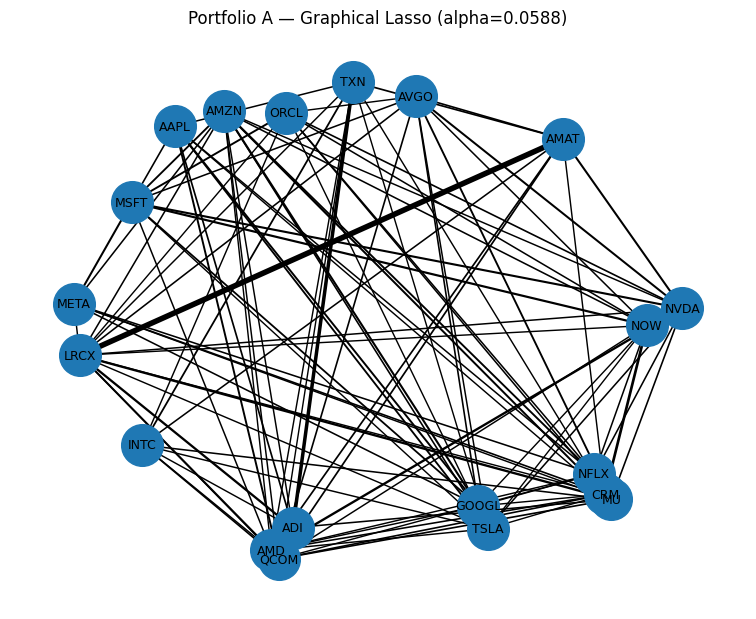

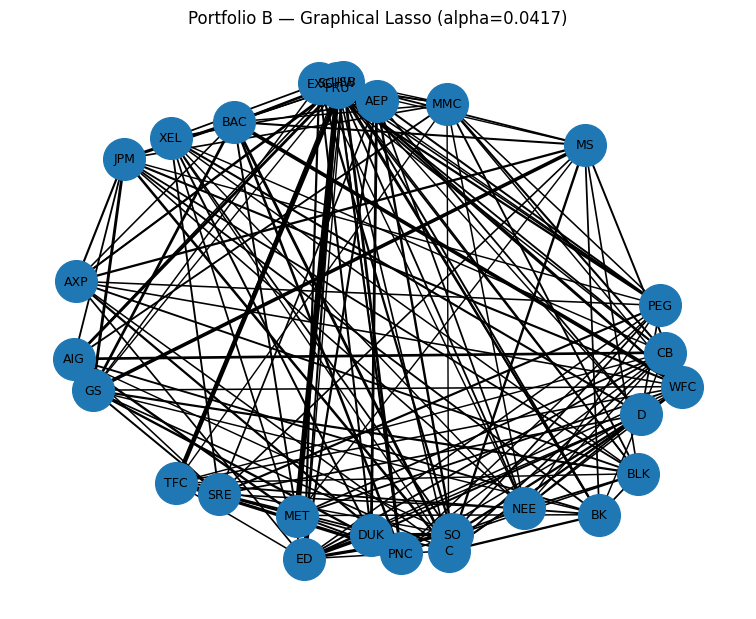

/Users/yingxuanyang/miniforge3/envs/tf-apple/lib/python3.11/site-packages/sklearn/covariance/_graph_lasso.py:191: ConvergenceWarning: graphical_lasso: did not converge after 100 iteration: dual gap: -2.684e-03
  warnings.warn(
/Users/yingxuanyang/miniforge3/envs/tf-apple/lib/python3.11/site-packages/sklearn/covariance/_graph_lasso.py:191: ConvergenceWarning: graphical_lasso: did not converge after 100 iteration: dual gap: -1.674e-03
  warnings.warn(
/Users/yingxuanyang/miniforge3/envs/tf-apple/lib/python3.11/site-packages/sklearn/covariance/_graph_lasso.py:191: ConvergenceWarning: graphical_lasso: did not converge after 100 iteration: dual gap: 4.276e-03
  warnings.warn(
/Users/yingxuanyang/miniforge3/envs/tf-apple/lib/python3.11/site-packages/sklearn/covariance/_graph_lasso.py:191: ConvergenceWarning: graphical_lasso: did not converge after 100 iteration: dual gap: 1.578e-03
  warnings.warn(
/Users/yingxuanyang/miniforge3/envs/tf-apple/lib/python3.11/site-packages/sklearn/covariance/_

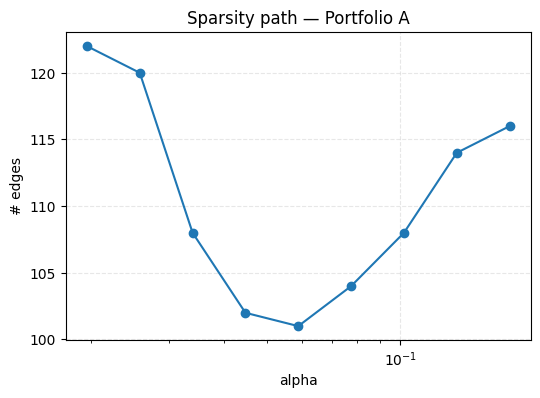

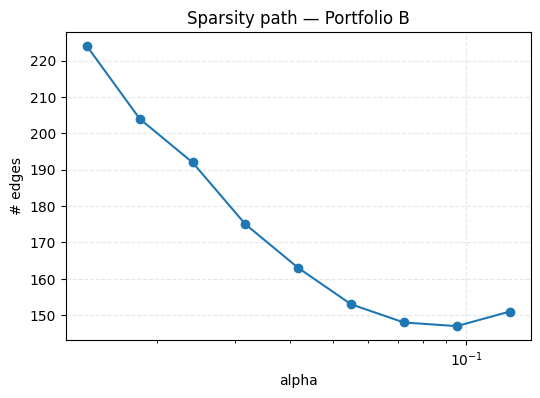

In [4]:
# --- Setup ---
import io, os, re, math, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.covariance import GraphicalLassoCV, GraphicalLasso
from sklearn.preprocessing import StandardScaler

# --- Data paths ---
WEEKLY_URL = "https://raw.githubusercontent.com/YData123/sds365-fa25/main/assignments/assn3/full_stock_weekly.csv"
DAILY_URL  = "https://raw.githubusercontent.com/YData123/sds365-fa25/main/assignments/assn3/full_stock_daily.csv"

# Choose weekly
df_px = pd.read_csv(WEEKLY_URL, parse_dates=['date']).set_index('date').sort_index()

# --- Portfolios ---
portfolio_A = ['AAPL','MSFT','NVDA','AMD','INTC','AVGO','QCOM','TXN','ADI','MU','AMAT','LRCX','CRM','ORCL','NOW','META','GOOGL','AMZN','NFLX','TSLA']
portfolio_B = ['JPM','BAC','WFC','C','GS','MS','PNC','USB','TFC','BK','SCHW','AXP','BLK','MMC','CB','AIG','MET','PRU',
               'NEE','SO','DUK','D','AEP','EXC','XEL','SRE','PEG','ED']

start, end = pd.Timestamp('2022-01-01'), pd.Timestamp('2025-09-30')

def make_returns(df_px, tickers, start, end, min_coverage=0.95):
    df = df_px.loc[(df_px.index>=start)&(df_px.index<=end), tickers].copy()
    # Filter symbols by coverage
    covg = 1 - df.isna().mean(axis=0)
    keep = covg.index[covg>=min_coverage].tolist()
    dropped = sorted(set(tickers) - set(keep))
    df = df[keep]
    # Log returns
    r = np.log(df).diff().iloc[1:]
    # Complete cases (no NAs across symbols/dates)
    r = r.dropna(axis=0, how='any')
    return r, keep, dropped

R_A, kept_A, dropped_A = make_returns(df_px, portfolio_A, start, end, min_coverage=0.95)
R_B, kept_B, dropped_B = make_returns(df_px, portfolio_B, start, end, min_coverage=0.95)

print("Portfolio A kept:", len(kept_A), kept_A)
print("Portfolio A dropped (coverage <95%):", dropped_A)
print("Portfolio B kept:", len(kept_B), kept_B)
print("Portfolio B dropped (coverage <95%):", dropped_B)

# Standardize features (columns)
scalerA = StandardScaler(with_mean=True, with_std=True).fit(R_A.values)
ZA = pd.DataFrame(scalerA.transform(R_A.values), index=R_A.index, columns=R_A.columns)

scalerB = StandardScaler(with_mean=True, with_std=True).fit(R_B.values)
ZB = pd.DataFrame(scalerB.transform(R_B.values), index=R_B.index, columns=R_B.columns)

# --- Fit Graphical Lasso with CV to choose alpha ---
glcv_A = GraphicalLassoCV(alphas=10, assume_centered=True)  # lets it pick alpha via internal CV
glcv_A.fit(ZA.values)
alpha_A = glcv_A.alpha_
Theta_A = glcv_A.precision_.copy()  # precision matrix
Sigma_A = glcv_A.covariance_.copy()

glcv_B = GraphicalLassoCV(alphas=10, assume_centered=True)
glcv_B.fit(ZB.values)
alpha_B = glcv_B.alpha_
Theta_B = glcv_B.precision_.copy()
Sigma_B = glcv_B.covariance_.copy()

print(f"Chosen alpha (A): {alpha_A:.4f}")
print(f"Chosen alpha (B): {alpha_B:.4f}")

# --- Build graphs from precision matrices ---
def precision_to_graph(Theta, labels, thresh=1e-8):
    """Undirected graph where an edge exists if off-diagonal precision != 0 (beyond small threshold)."""
    p = Theta.shape[0]
    G = nx.Graph()
    G.add_nodes_from(labels)
    for i in range(p):
        for j in range(i+1, p):
            if abs(Theta[i,j]) > thresh:
                G.add_edge(labels[i], labels[j], weight=Theta[i,j])
    return G

GA = precision_to_graph(Theta_A, ZA.columns.tolist())
GB = precision_to_graph(Theta_B, ZB.columns.tolist())

def draw_glasso_graph(G, title, outpath=None):
    plt.figure(figsize=(9.5, 7.5))
    pos = nx.spring_layout(G, seed=7, k=0.35)  # force layout
    # Edge widths scale with |precision|
    weights = np.array([abs(G[u][v]['weight']) for u,v in G.edges]) if G.number_of_edges() else np.array([])
    if len(weights) > 0:
        widths = 1 + 3 * (weights - weights.min())/(weights.ptp() + 1e-9)
    else:
        widths = []
    nx.draw_networkx_nodes(G, pos, node_size=900)
    nx.draw_networkx_labels(G, pos, font_size=9)
    nx.draw_networkx_edges(G, pos, width=widths)
    plt.title(title)
    plt.axis('off')
    if outpath:
        plt.savefig(outpath, bbox_inches='tight', dpi=160)
    plt.show()

draw_glasso_graph(GA, f"Portfolio A — Graphical Lasso (alpha={alpha_A:.4f})", outpath="glasso_portfolio_A.png")
draw_glasso_graph(GB, f"Portfolio B — Graphical Lasso (alpha={alpha_B:.4f})", outpath="glasso_portfolio_B.png")

# --- Sensitivity: sparsity vs alpha ---
def sparsity_path(Z, alphas):
    edges = []
    for a in alphas:
        mdl = GraphicalLasso(alpha=a, assume_centered=True).fit(Z.values)
        Th = mdl.precision_
        nz = (np.abs(np.triu(Th, 1)) > 1e-8).sum()
        edges.append(nz)
    return pd.DataFrame({"alpha": alphas, "num_edges": edges})

alphas_A = np.geomspace(alpha_A/3, alpha_A*3, 9)
alphas_B = np.geomspace(alpha_B/3, alpha_B*3, 9)

spA = sparsity_path(ZA, alphas_A)
spB = sparsity_path(ZB, alphas_B)

plt.figure(figsize=(6,4))
plt.plot(spA['alpha'], spA['num_edges'], marker='o')
plt.xscale('log'); plt.xlabel('alpha'); plt.ylabel('# edges'); plt.title('Sparsity path — Portfolio A')
plt.grid(True, ls='--', alpha=0.3)
plt.savefig("sparsity_path_A.png", bbox_inches='tight', dpi=160)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(spB['alpha'], spB['num_edges'], marker='o')
plt.xscale('log'); plt.xlabel('alpha'); plt.ylabel('# edges'); plt.title('Sparsity path — Portfolio B')
plt.grid(True, ls='--', alpha=0.3)
plt.savefig("sparsity_path_B.png", bbox_inches='tight', dpi=160)
plt.show()



# Graphical Lasso on Two Stock Portfolios

## Data, Portfolios, and Preprocessing

**Data window and frequency.**  
I use weekly closes from **2022-01-01** to **2025-09-30**. Weekly sampling smooths microstructure noise and tends to produce more stable sparsity patterns.

**Returns and cleaning.**  
For each portfolio I compute log-returns of the weekly close, filter symbols to have at least \(95\%\) coverage over the window, and form a complete-cases matrix (no missing values across the selected dates and tickers). Columns are standardized to zero mean and unit variance prior to estimation.

**Portfolios (each ≥ 20 stocks).**
- **Portfolio A: U.S. Tech & Platforms (Growth).** Large-cap semiconductors, cloud/enterprise software, and consumer internet/platforms. 
- **Portfolio B: Rates-Sensitive (Financials + Utilities).** Money-center and regional banks, brokers/asset managers, insurers, and regulated utilities.

## Method: Graphical Lasso

The regularization level $\alpha$ controls sparsity: larger $\alpha$ yields fewer edges (more shrinkage), smaller $\alpha$ yields denser graphs. I select $\alpha$ by `GraphicalLassoCV` and then examine a local log-spaced grid to assess stability.

## Results

![Portfolio A Graph](glasso_portfolio_A.png)
![Portfolio B Graph](glasso_portfolio_B.png)

*Figure 1. Estimated conditional-dependence graphs. Left: Portfolio A at $\alpha=0.0588$. Right: Portfolio B at $\alpha=0.0417$. Edge widths scale with $|\hat\Theta_{ij}|$.*

![Sparsity Path A](sparsity_path_A.png)
![Sparsity Path B](sparsity_path_B.png)

*Figure 2. Sparsity paths: number of edges vs. $\alpha$ (log scale).*

### Portfolio A (Tech & Platforms)

**Graph structure.**  
The graph is organized into intuitive sub-communities:

- A **semiconductor cluster** (e.g., fabrication & equipment names) with strong edges such as $\mathrm{AMAT}\!-\!\mathrm{LRCX}$ and connections among $\mathrm{NVDA}, \mathrm{AMD}, \mathrm{QCOM}, \mathrm{ADI}, \mathrm{TXN}$.
- A **cloud/enterprise** pocket (e.g., $\mathrm{MSFT}, \mathrm{ORCL}, \mathrm{CRM}, \mathrm{NOW}$), sometimes bridging to hyperscaler names ($\mathrm{AMZN}, \mathrm{GOOGL}$).
- **Consumer platforms** ($\mathrm{META}, \mathrm{NFLX}, \mathrm{TSLA}$) connect more selectively to the above, reflecting residual ties after conditioning on the rest of the universe.

Hubs such as $\mathrm{MSFT}$ or $\mathrm{AAPL}$ often maintain multiple links across sub-sectors.

**Regularization choice and sensitivity.**  
Cross-validation selects $\alpha=0.0588$.  
The sparsity path (Figure 2, left) is mostly decreasing, with a trough near $\sim\!0.05$ where the edge count is lowest (about $10^2$). The mild non-monotonicity at the right end is typical of numerical tolerances/thresholding; qualitatively, the community structure is stable around the CV pick. At much larger $\alpha$ the inter-subsector bridges drop first, leaving tight intra-semiconductor and intra-cloud blocks.

**Conditional independences.**  
Missing edges between, for example, a streaming platform ($\mathrm{NFLX}$) and a fab-equipment name ($\mathrm{LRCX}$) indicate that their raw correlation is largely explained through mediators (market/tech factors captured by other nodes). Thus, given the rest of the portfolio, those pairs are (approximately) conditionally independent.

### Portfolio B (Financials + Utilities)

**Graph structure.**  
Two clear modules emerge:

- A **financials** community (money-center/regional banks, brokers/asset managers, card/credit, insurers). Banks are densely connected; insurers ($\mathrm{CB},\mathrm{AIG},\mathrm{MET},\mathrm{PRU}$) form a nearby sub-block with selective links to banks and brokers.
- A **utilities** community ($\mathrm{NEE},\mathrm{SO},\mathrm{DUK},\mathrm{AEP},\mathrm{EXC},\mathrm{ED},\ldots$) with strong within-sector ties reflecting common rate/regulatory exposure.

Only a few bridges connect utilities to financials, consistent with the idea that co-movement across these groups is predominantly explained by shared macro rate shocks.

**Regularization choice and sensitivity.**  
Cross-validation selects $\alpha=0.0417$.  
The sparsity path (Figure 2, right) is close to monotone: as $\alpha$ increases, edges fall from $\sim\!225$ to a shallow minimum near $\sim\!0.09$, then tick up slightly. The qualitative sectoral separation and internal density are robust across the grid; larger $\alpha$ mainly prunes cross-sector bridges.

**Conditional independences.**  
The near-absence of edges between (say) a utility and an investment bank implies that, once we condition on other financials/utilities (which proxy for the rate and credit channels), there is little direct residual dependence between such pairs.

## Takeaways

- The learned graphs align with economic intuition: dense within-sector connectivity and sparse between-sector links.
- Cross-validated $\alpha$ yields stable structures; sensitivity checks confirm that core communities persist across a reasonable range.
- Interpreting zeros in $\hat\Theta$ as conditional independences highlights which apparent correlations are explained away by the rest of the universe, providing a cleaner view of sectoral risk transmission.
